# 8 · True 2-D flexural backstripping of a correlated section

**What.** Correlate the eight North Viking Graben wells into a cross-section, then backstrip the whole section at once: strip the top unit, decompact everything below it at every point along the line, and let an elastic plate (not independent columns) rebound under the removed load. This is the method of Watts et al. (1982), Kusznir et al. (1995) and Roberts et al. (1998).

**Why it differs from Notebook 7.** Notebook 7 ran 1-D Airy backstrips at each well and only afterwards replaced the Airy sediment correction by a plate deflection of the interpolated load. Here decompaction, loading and rebound are all computed on the section grid, and the restored sections come directly from the plate.

**References.** Watts, A.B. (2001) *Isostasy and Flexure of the Lithosphere*, CUP (ch. 3 & 6). Kusznir, N.J., Roberts, A.M. & Morley, C.K. (1995) Forward and reverse modelling of rift basin formation, *Geol. Soc. Spec. Publ.* 80, 33–56. Roberts, A.M., Kusznir, N.J., Yielding, G. & Styles, P. (1998) 2D flexural backstripping of extensional basins: the need for a sideways glance, *Petroleum Geoscience* 4, 327–338. Allen, P.A. & Allen, J.R. (2013) *Basin Analysis*, 3rd ed., Wiley (ch. 2 flexure, ch. 9 backstripping). Turcotte, D.L. & Schubert, G. (2014) *Geodynamics*, 3rd ed., CUP, s. 3.17 (plate flexure).

## Equations (Geological Digressions style)

**1 · Correlation.** Each unit $j$ is correlated by name. Its present thickness at the wells, $h_j(x_w)$, is linearly interpolated to a regular grid $x$ ($\Delta x$ = 500 m). A unit missing in a well has $h_j = 0$ there, so it pinches out between wells.

**2 · Porosity–depth law** (mixed lithology, fractions $F_k$): $\displaystyle \phi(z)=\sum_k F_k\,\phi_{0k}\,e^{-z/C_k}$

**3 · Decompaction** — grain (solid) thickness is conserved when a layer moves from depth $D$ to $D'$:
$$G_j=T_j-\sum_k F_k C_k\phi_{0k}\,e^{-D_j/C_k}\left(1-e^{-T_j/C_k}\right)=T'_j-\sum_k F_k C_k\phi_{0k}\,e^{-D'_j/C_k}\left(1-e^{-T'_j/C_k}\right)$$
solved for $T'_j$ by Newton iteration at every $x$.

**4 · Load** of the remaining decompacted column $S(x)=\sum_j T'_j$ with bulk density $\bar\rho_s=\sum_j[\rho_g G_j+\rho_w(T'_j-G_j)]/S$, in a water-filled basin:
$$q(x)=(\bar\rho_s-\rho_w)\,g\,S(x)$$

**5 · Thin elastic plate**:
$$D\,\frac{d^4w}{dx^4}+(\rho_m-\rho_w)\,g\,w=q(x),\qquad D=\frac{E\,T_e^3}{12(1-\nu^2)}$$
solved by FFT (continuous plate, $W(k)=Q(k)/[Dk^4+(\rho_m-\rho_w)g]$) or by finite differences (variable $T_e$, or a broken plate with free ends). When $T_e\to0$, $w\to q/[(\rho_m-\rho_w)g]$, which is Airy.

**6 · Water-loaded tectonic subsidence along the section**:
$$Z(x,t)=W(x,t)-\Delta SL(t)\,\frac{\rho_m}{\rho_m-\rho_w}+S(x,t)-w(x,t)$$
With $T_e=0$ this is exactly the 1-D Airy formula of Notebook 3: $Z=S\frac{\rho_m-\bar\rho_s}{\rho_m-\rho_w}+W-\Delta SL\frac{\rho_m}{\rho_m-\rho_w}$.

**7 · Reverse post-rift modelling** (Roberts et al. 1998, steps 1–6). Start from the present section with base depth $B_0(x)$. At age $t$:
$$B(x,t)=B_0-\big[w_0(x)-w_t(x)\big]-\Delta Z_{th}(x,t)+\big(\Delta SL_t-\Delta SL_0\big)\frac{\rho_w}{\rho_m-\rho_w},\qquad \text{seafloor}=B-S_t$$
$\Delta Z_{th}=S_{th}(t_r)-S_{th}(t_r-t)$ is the McKenzie water-loaded thermal subsidence since $t$ ($t_r$ = time since end of rifting today). The restored paleo-water depth is a **prediction**. In the Airy method it is an input instead.

| symbol | meaning | value |
|---|---|---|
| $\phi_0, C$ | surface porosity, compaction length | per lithology (Sclater & Christie 1980) |
| $\rho_g,\rho_w,\rho_m$ | grain, water, mantle density | lithology, 1025, 3300 kg m⁻³ |
| $E,\nu$ | Young's modulus, Poisson's ratio | 70 GPa, 0.25 (all defaults: `pybasinsubs.constants`) |
| $T_e$ | effective elastic thickness | 1.5 km (Roberts et al. 1998) unless stated |
| $w$ | plate deflection under the sediment load (+ down) | |
| $W,\Delta SL$ | paleo-water depth, eustatic sea level | well data, Miller et al. 2020 |
| $\beta$ | McKenzie stretching factor | fitted |

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)
from pybasinsubs import faultfit as FF
from pybasinsubs import data_path, flex2d
from pybasinsubs.flexure import rigidity
from pybasinsubs.column import from_sodir
from pybasinsubs.backstrip import backstrip
from pybasinsubs.plotting import ics_color, C_WATERFILL, C_LAND

## 1 · Concept: how 2-D flexural backstripping works

A synthetic section: a post-rift fill (400 m, thickening to ~1.5 km over the half-grabens) over a saw-tooth Jurassic syn-rift fill (half-grabens 25 km wide) on a 1 km pre-rift layer, all shale, under 200 m of water. We remove the top unit and follow the steps.

saved image/nb8_concept_2d_flexural_backstripping.png


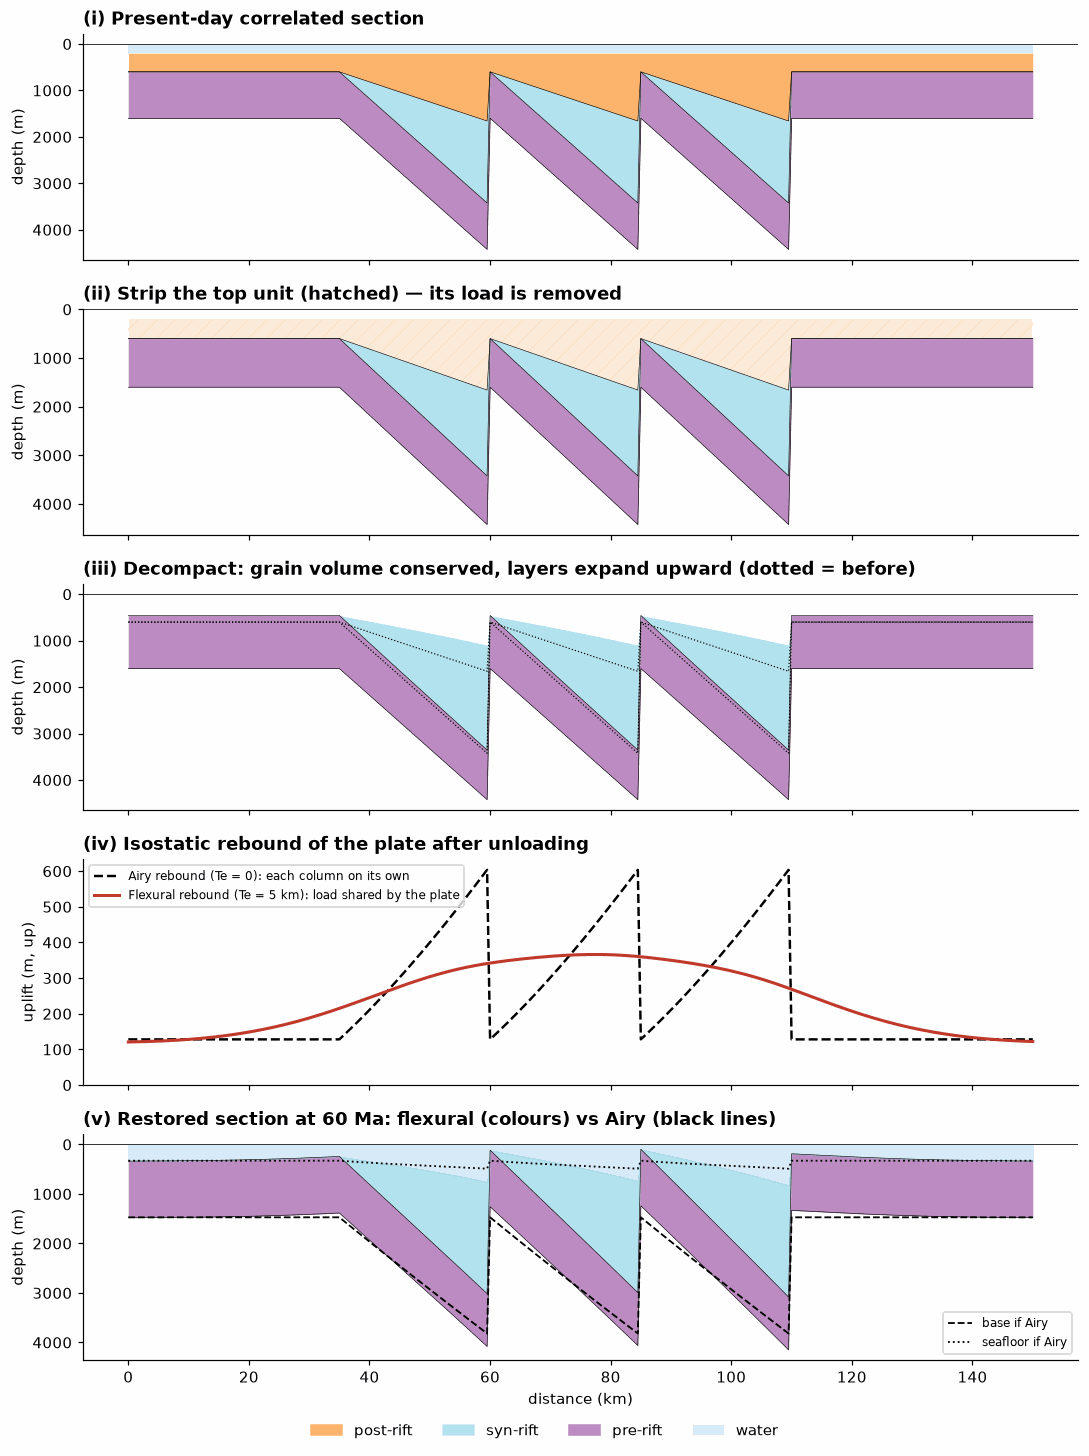

In [2]:
x = np.arange(0, 150e3 + 1, 500.0)
saw = 1800 * ((x - 10e3) % 25e3) / 25e3 * ((x > 35e3) & (x < 110e3))
h = np.array([400.0 + 0.6 * saw, saw, np.full_like(x, 1000.0)])   # post-rift onlap fill thickens over the half-grabens
lt = from_sodir("30/4-1").lithologies.loc[["shale"]]
syn = flex2d.Section(x=x, units=["post-rift", "syn-rift", "pre-rift"], age_top=np.array([0., 60., 150.]), age_base=np.array([60., 150., 200.]),
                     h=h, F=np.ones((3, len(x), 1)), W=np.array([np.full_like(x, 200.)] * 3), SL=np.zeros(3), W0=np.full_like(x, 200.),
                     phi0=lt.phi0.to_numpy(float), C=lt.C.to_numpy(float), rho_g=lt.rho_g.to_numpy(float))
rf = flex2d.backstrip_section(syn, Te=5e3); ra = flex2d.backstrip_section(syn, Te=0.0)
cols = ["#FDB46C", "#B3E3EE", "#BD8CC3"]; xs = x / 1e3
fig, axs = plt.subplots(5, 1, figsize=(10, 13), sharex=True)
def draw(ax, tops, bases, which, alpha=1, hatch=None):
    for k in which:
        ax.fill_between(xs, tops[k], bases[k], color=cols[k], alpha=alpha, lw=0, hatch=hatch, edgecolor="grey")
        ax.plot(xs, bases[k], "k", lw=.4)
# (i) present
draw(axs[0], rf.top[0], rf.base[0], [0, 1, 2]); axs[0].fill_between(xs, 0, rf.top[0][0], color=C_WATERFILL, alpha=.25)
axs[0].set_title("(i) Present-day correlated section", loc="left", fontweight="bold")
# (ii) strip top unit (no compaction change, no rebound)
draw(axs[1], rf.top[0], rf.base[0], [0], alpha=.25, hatch="//"); draw(axs[1], rf.top[0], rf.base[0], [1, 2])
axs[1].set_title("(ii) Strip the top unit (hatched) — its load is removed", loc="left", fontweight="bold")
# (iii) decompact remaining units, base held fixed
B0 = rf.base[0][2]; S1 = rf.S[1]; top_d = rf.top[1] - rf.seafloor[1] + (B0 - S1); base_d = rf.base[1] - rf.seafloor[1] + (B0 - S1)
for k in (1, 2): axs[2].plot(xs, rf.top[0][k], color="k", ls=":", lw=.8)
draw(axs[2], top_d, base_d, [1, 2]); axs[2].set_title("(iii) Decompact: grain volume conserved, layers expand upward (dotted = before)", loc="left", fontweight="bold")
# (iv) rebound
dwf = rf.w[0] - rf.w[1]; dwa = ra.w[0] - ra.w[1]
axs[3].plot(xs, dwa, "k--", lw=1.6, label="Airy rebound (Te = 0): each column on its own")
axs[3].plot(xs, dwf, color="#c0392b", lw=2, label="Flexural rebound (Te = 5 km): load shared by the plate")
axs[3].axhline(0, color="grey", lw=.5); axs[3].set_ylabel("uplift (m, up)"); axs[3].set_ylim(0, None)
axs[3].legend(fontsize=8, loc="upper left"); axs[3].set_title("(iv) Isostatic rebound of the plate after unloading", loc="left", fontweight="bold")
# (v) restored: flexural, plus Airy base for comparison
draw(axs[4], rf.unloaded_base[1][None] * 0 + (top_d - dwf), base_d - dwf, [1, 2])
axs[4].fill_between(xs, 0, rf.unloaded_seafloor[1], where=rf.unloaded_seafloor[1] > 0, color=C_WATERFILL, alpha=.25)
axs[4].plot(xs, ra.unloaded_base[1], "k--", lw=1.2, label="base if Airy")
axs[4].plot(xs, ra.unloaded_seafloor[1], "k:", lw=1.2, label="seafloor if Airy")
axs[4].legend(fontsize=8, loc="lower right"); axs[4].set_title("(v) Restored section at 60 Ma: flexural (colours) vs Airy (black lines)", loc="left", fontweight="bold")
for i, ax in enumerate(axs):
    if i != 3: ax.invert_yaxis(); ax.axhline(0, color="k", lw=.5); ax.set_ylabel("depth (m)")
axs[-1].set_xlabel("distance (km)")
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(cols, syn.units)] + [Patch(color=C_WATERFILL, alpha=.25, label="water")],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(.5, -.02))
fig.tight_layout(); save(fig, "nb8_concept_2d_flexural_backstripping.png"); plt.show()

**Reading.** (i) The present section. (ii) Taking off the top unit removes its weight. (iii) The units below are now shallower, so their pores re-open and they thicken. Grain volume stays fixed, so a thick half-graben fill expands more than a thin footwall crest. (iv) The plate rises because the load came off. With Airy (dashed) each column rises by its own unloading, so the rebound copies the saw-tooth. A plate with T_e = 5 km smooths it: the footwall highs rise less than Airy says, and the depocentres rise less too, because the stiff plate averages over about 2πα (α = flexural parameter). (v) The restored section. In Airy (black lines) the graben floors come back too deep and the crests too shallow, so the blocks deform internally. Flexure moves each block more uniformly and keeps its shape. This is the "sideways glance" of Roberts et al. (1998).

## 2 · Validation

**(a) Analytic plate solutions.** Line load $V_0$ on a continuous plate (Turcotte & Schubert 2014, s. 3.17): $w=\frac{V_0\alpha^3}{8D}e^{-|x|/\alpha}\left(\cos\frac{|x|}{\alpha}+\sin\frac{|x|}{\alpha}\right)$, $\alpha=\left[\frac{4D}{(\rho_m-\rho_w)g}\right]^{1/4}$. Broken plate with the load at the free end: $w=\frac{V_0\alpha^3}{4D}e^{-x/\alpha}\cos\frac{x}{\alpha}$. Load conservation: $\int(\rho_m-\rho_w)g\,w\,dx=\int q\,dx$.

**(b) Published numbers we can reproduce exactly** (Roberts et al. 1998, *Pet. Geosci.* 4):
1. *"a flexural rigidity of c. 1.7×10²⁰ N m is equivalent to an effective elastic thickness of c. 3 km"* (section "2D backstripping using flexural isostasy").
2. Fig. 7c and text on p. 335. Using E = 10¹¹ N m⁻², ν = 0.25, ρ_m = 3300, ρ_i = 1000 kg m⁻³, the complementary compensation function is $F=1-\frac{(\rho_m-\rho_i)g}{(\rho_m-\rho_i)g+Dk^4}$. The paper says that for T_e = 1 km, F = 50 % at λ ≈ 30 km, and for T_e = 3 km, loads with λ < 60 km are more than 50 % flexurally compensated.

**(c) Internal consistency:** T_e = 0 on the section must equal the 1-D Airy backstrip (Notebook 3 engine, `mixing="mixed"`) at every well and age.

In [3]:
dr = 3300 - 1025; Te = 10e3; dx = 250.0
xx = np.arange(-300e3, 300e3 + dx, dx); V0 = 1e12
q = np.zeros_like(xx); q[len(xx) // 2] = V0 / dx
wn = flex2d.plate_deflection(q, dx, Te, dr, method="fd"); wa = flex2d.line_load_analytic(xx, V0, Te, dr)
wnf = flex2d.plate_deflection(q, dx, Te, dr, method="fft")
i0 = len(xx) // 2; qb = np.zeros_like(xx); qb[i0] = V0 / dx    # broken plate: V0/2 on the free end of the right half (T&S: V0 shared by both halves)
wb = flex2d.plate_deflection(qb, dx, Te, dr, break_index=i0)
wba = flex2d.line_load_analytic(xx, V0, Te, dr, broken=True)
err = lambda a, b: np.max(abs(a - b)) / np.max(abs(b))
cons = (dr * 9.81 * wn).sum() * dx / V0
res = pd.DataFrame({"test": ["continuous FD vs analytic", "continuous FFT vs analytic", "broken FD vs analytic (x>=0)", "load conservation ∫Δρgw / ∫q"],
                    "result": [f"{100*err(wn, wa):.2f} % max error", f"{100*err(wnf, wa):.2f} % max error", f"{100*err(wb[i0:], wba[i0:]):.2f} % max error", f"{cons:.5f}"]})
# Roberts et al. 1998 numbers
D3 = rigidity(3e3); E11 = lambda Te: 1e11 * Te**3 / (12 * (1 - .25**2))
lam50 = lambda Te: 2 * np.pi / ((2300 * 9.81) / E11(Te)) ** 0.25
res.loc[len(res)] = ["D for Te = 3 km (E = 70 GPa) vs Roberts '1.7e20 N m'", f"{D3:.2e} N m"]
res.loc[len(res)] = ["λ where F = 50 %, Te = 1 km vs Roberts '≈30 km'", f"{lam50(1e3)/1e3:.1f} km"]
res.loc[len(res)] = ["λ where F = 50 %, Te = 3 km vs Roberts '<60 km'", f"{lam50(3e3)/1e3:.1f} km"]
res

,test,result
0,continuous FD vs analytic,0.03 % max error
1,continuous FFT vs analytic,0.00 % max error
2,broken FD vs analytic (x>=0),0.01 % max error
3,load conservation ∫Δρgw / ∫q,1.00000
4,D for Te = 3 km (E = 70 GPa) vs Roberts '1.7e2...,1.68e+20 N m
5,"λ where F = 50 %, Te = 1 km vs Roberts '≈30 km'",28.0 km
6,"λ where F = 50 %, Te = 3 km vs Roberts '<60 km'",63.8 km


saved image/nb8_validation.png


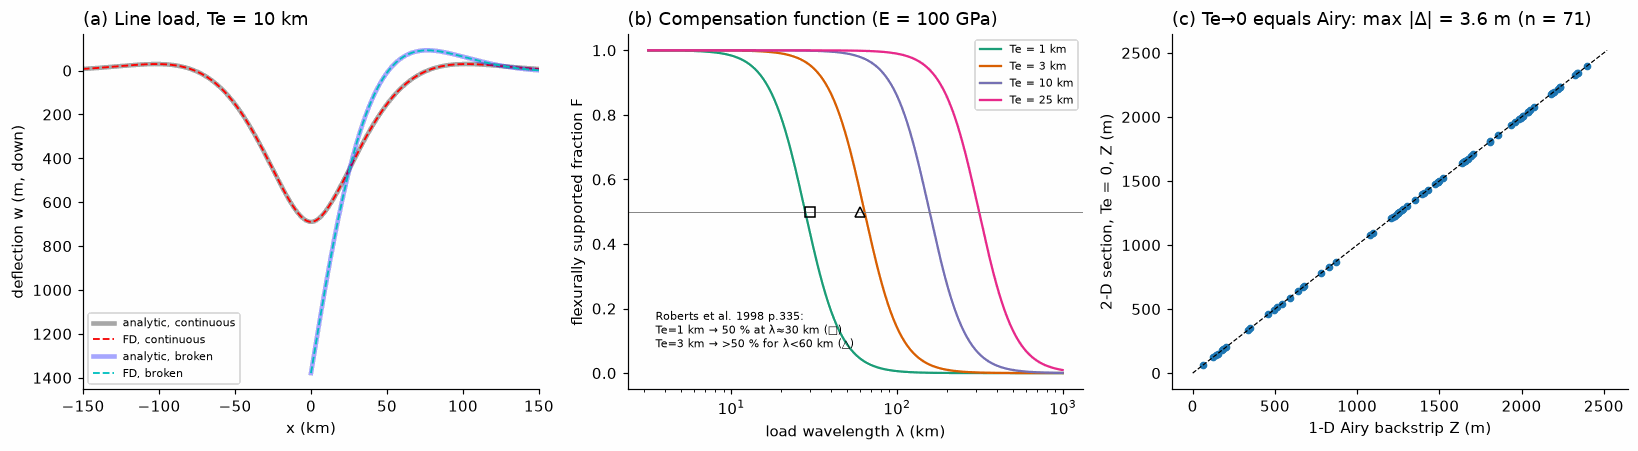

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
s = xx / 1e3
axs[0].plot(s, wa, "k", lw=3, alpha=.35, label="analytic, continuous"); axs[0].plot(s, wn, "r--", lw=1.2, label="FD, continuous")
axs[0].plot(s[i0:], wba[i0:], color="b", lw=3, alpha=.35, label="analytic, broken"); axs[0].plot(s[i0:], wb[i0:], "c--", lw=1.2, label="FD, broken")
axs[0].set_xlim(-150, 150); axs[0].invert_yaxis(); axs[0].set_xlabel("x (km)"); axs[0].set_ylabel("deflection w (m, down)")
axs[0].set_title("(a) Line load, Te = 10 km", loc="left"); axs[0].legend(fontsize=7)
lam = np.logspace(0.5, 3, 300) * 1e3; k = 2 * np.pi / lam
for Te_, c in zip([1e3, 3e3, 10e3, 25e3], ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]):
    F = 1 - 2300 * 9.81 / (2300 * 9.81 + E11(Te_) * k**4)
    axs[1].semilogx(lam / 1e3, F, color=c, label=f"Te = {Te_/1e3:g} km")
axs[1].axhline(.5, color="grey", lw=.6); axs[1].plot([30], [.5], "ks", ms=7, mfc="none"); axs[1].plot([60], [.5], "k^", ms=7, mfc="none")
axs[1].annotate("Roberts et al. 1998 p.335:\nTe=1 km → 50 % at λ≈30 km (□)\nTe=3 km → >50 % for λ<60 km (△)", (3.5, .08), fontsize=7)
axs[1].set_xlabel("load wavelength λ (km)"); axs[1].set_ylabel("flexurally supported fraction F")
axs[1].set_title("(b) Compensation function (E = 100 GPa)", loc="left"); axs[1].legend(fontsize=7, loc="upper right")
VG = pd.read_csv(data_path("north_sea", "sodir_viking_graben_wells.csv")).sort_values("lon")
cols_ = [from_sodir(w) for w in VG.well]
xw = ((VG.lon - VG.lon.min()) * 111.32e3 * np.cos(np.radians(VG.lat.mean()))).to_numpy()
sec = flex2d.correlate(cols_, xw, dx=500.0)
sec50 = flex2d.correlate(cols_, xw, dx=50.0)            # fine grid so the wells fall within 25 m of a node
r0 = flex2d.backstrip_section(sec50, 0.0)
pairs = []
for i, c in enumerate(cols_):
    sm = backstrip(c, n=0, mc=False, mixing="mixed").summary(); d = dict(zip(sm.age_Ma.round(2), sm.tectonic_subsidence_m))
    u = c.units.set_index("unit")
    for kk, a in enumerate(sec50.age_top):
        nm = sec50.units[kk]
        # compare only nodes where the well actually has this unit (no hiatus re-interpretation)
        if round(a, 2) in d and nm in u.index and u.loc[nm, "thickness_m"] > 0:
            pairs.append((c.name, a, d[round(a, 2)], np.interp(sec50.xw[i], sec50.x, r0.Z[kk])))
pairs = pd.DataFrame(pairs, columns=["well", "age", "Z_1D", "Z_2D_Te0"])
axs[2].plot(pairs.Z_1D, pairs.Z_2D_Te0, "o", ms=4); lim = [0, pairs[["Z_1D", "Z_2D_Te0"]].max().max() * 1.05]
axs[2].plot(lim, lim, "k--", lw=.8); axs[2].set_xlabel("1-D Airy backstrip Z (m)"); axs[2].set_ylabel("2-D section, Te = 0, Z (m)")
axs[2].set_title(f"(c) Te→0 equals Airy: max |Δ| = {abs(pairs.Z_1D - pairs.Z_2D_Te0).max():.1f} m (n = {len(pairs)})", loc="left")
fig.tight_layout(); save(fig, "nb8_validation.png"); plt.show()

**Reading.** (a) The numerical plate (dashed) sits on the textbook curves for both a continuous and a broken plate. The table gives errors of a few tenths of a percent from grid discretisation, and the plate supports exactly the applied load. (b) The curves reproduce Roberts et al.'s (1998) Fig. 7c statements. With their E = 100 GPa, half of a 28 km-wavelength load is supported flexurally at T_e = 1 km, and at T_e = 3 km the 50 % point is at about 64 km. Both agree with "≈30 km" and "<60 km" at the precision the paper gives. With our E = 70 GPa, T_e = 3 km gives D = 1.68×10²⁰ N m, matching their "c. 1.7×10²⁰ N m". (c) With T_e = 0, the 2-D section code returns the same tectonic subsidence as the independent 1-D Airy engine at every well and age. The few-metre residual is grid sampling: it is up to ~30 m at Δx = 500 m and shrinks as the grid is refined, because the wells do not sit exactly on grid nodes and the thickness kinks at the wells.

**What we cannot reproduce.** Roberts et al. (1998) backstripped seismic depth sections (their Figs 4–6: lines Viking Graben 1 and 2, Central Graben) with 10 interpreted horizons, fault blocks, a Triassic β = 1.2 and Haq et al. (1987) eustasy. Those sections are not published as numbers, and our eight-well line follows a different track. So we cannot compare restored geometries point by point. We adopt their best-fit **T_e = 1.5 km** (range 1.5–3 km; text discussing Fig. 4, which is also the value used by Roberts et al. 2019, *Pet. Geosci.* 25) and compare our fitted β only qualitatively with their Late Jurassic β ≈ 1.15 (forward-model range 1.1–1.2).

## 3 · Viking transect: correlated section and flexural restoration

In [5]:
TE = 1500.0; RIFT_END = 140.0
rf = flex2d.backstrip_section(sec, TE); ra = flex2d.backstrip_section(sec, 0.0)
rows = []
for Te_, r in [(0.0, ra), (TE, rf)] + [(t, flex2d.backstrip_section(sec, t)) for t in (3e3, 10e3)]:
    b, m, _, _ = flex2d.fit_beta_section(r, sec, RIFT_END)
    rows.append(dict(Te_km=Te_ / 1e3, best_beta=b, rms_water_depth_misfit_m=m))
fitb = pd.DataFrame(rows); BETA = float(fitb.loc[fitb.Te_km == TE / 1e3, "best_beta"].iloc[0]); fitb.round(2)

,Te_km,best_beta,rms_water_depth_misfit_m
0,0.0,1.26,213.53
1,1.5,1.26,243.40
2,3.0,1.26,251.97
3,10.0,1.26,315.54


β is chosen so that the restored paleo-water depths best match the well paleo-water depth estimates at the 8 wells for post-rift ages (0–140 Ma). The misfit (~200–300 m) is about the size of the uncertainty of those generic group-level estimates, so β is only loosely constrained. Note that T_e = 0 actually gives the *lowest* misfit here. That is expected when the 'observed' water depths are themselves generic values, set per unit and smoothly interpolated, rather than sea-level markers on fault-block crests. So these data **cannot** discriminate T_e, and we keep Roberts et al.'s calibrated 1.5 km. The values (~1.25) are a little above Roberts et al.'s β ≈ 1.15 for nearby lines, which is plausible because our wells sit mostly on highs and use no sea-level markers.

saved image/nb8_viking_restored_sequence.png


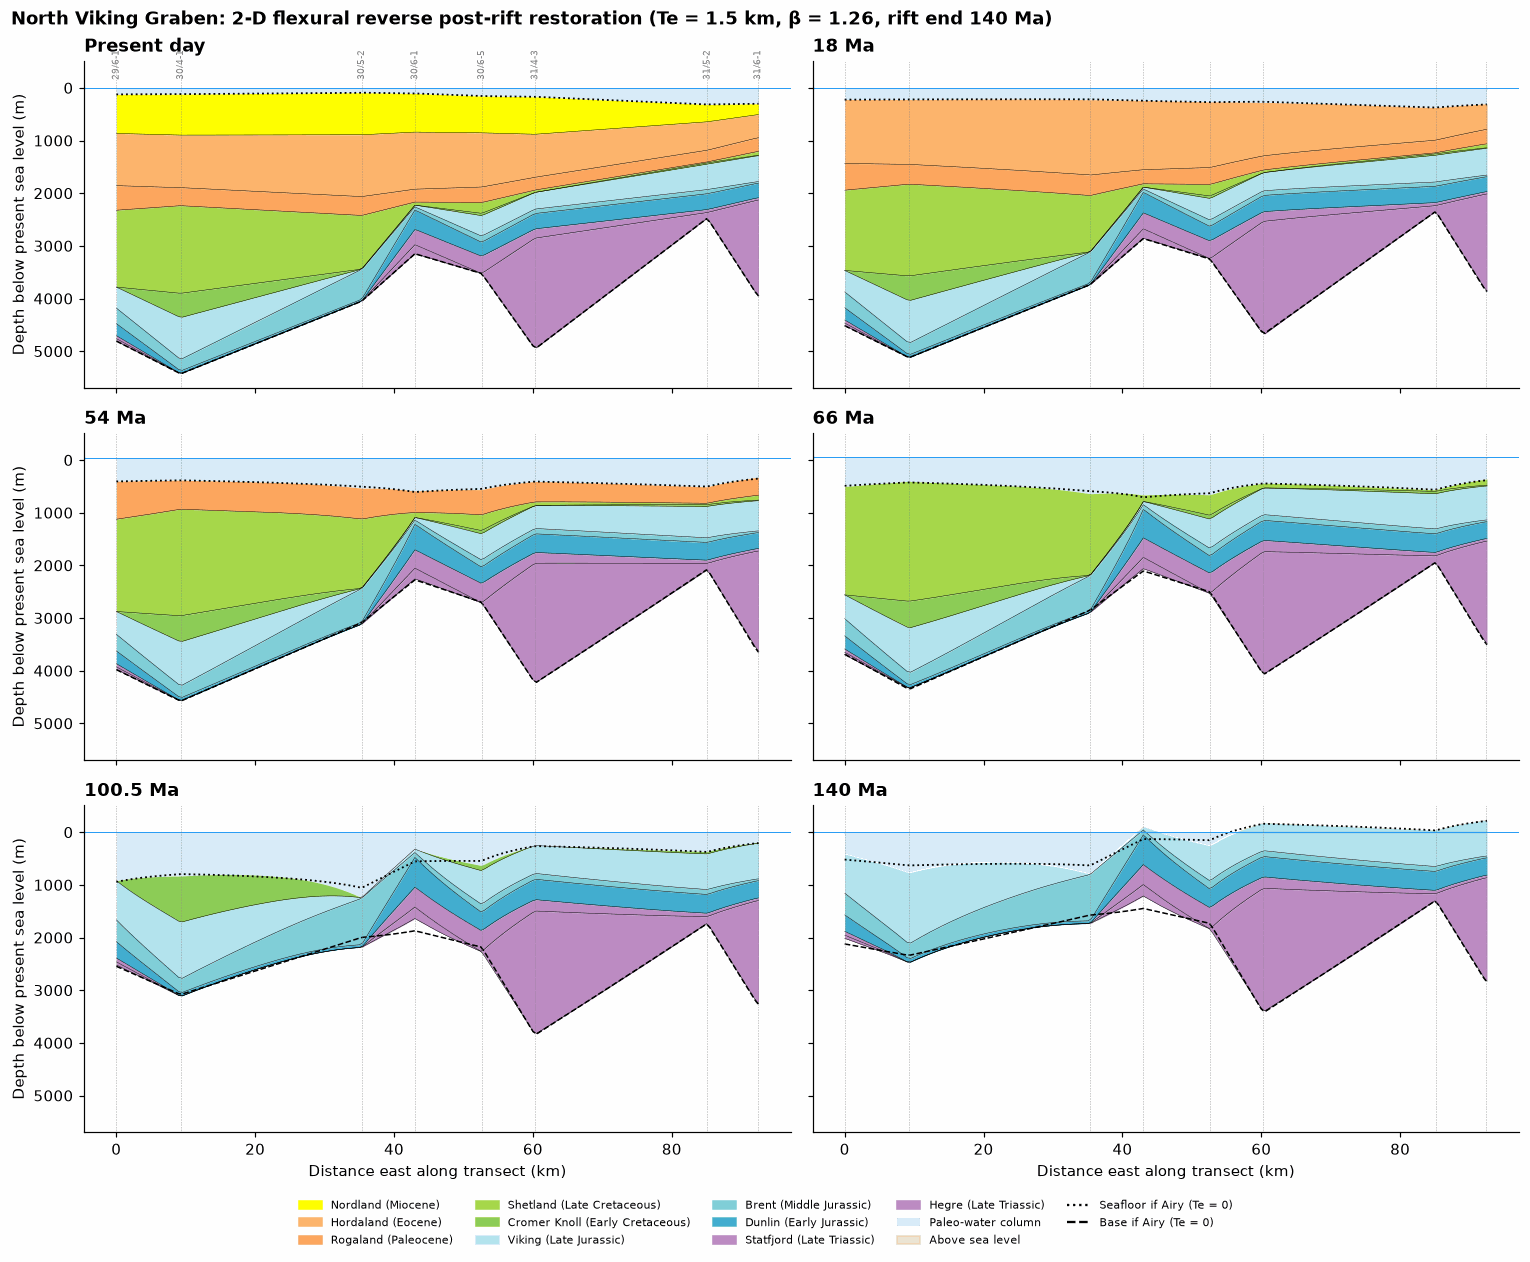

In [6]:
ages_show = [0.0, 18.0, 54.0, 66.0, 100.5, 140.0]
rp_f = flex2d.reverse_postrift(rf, sec, BETA, RIFT_END); rp_a = flex2d.reverse_postrift(ra, sec, BETA, RIFT_END)
xs = sec.x / 1e3
fig, axs = plt.subplots(3, 2, figsize=(14, 11), sharex=True, sharey=True)
hand = {}
for ax, a in zip(axs.flat, ages_show):
    i = int(np.where(np.isclose(rf.ages, a))[0][0]); ip = int(np.where(np.isclose(rp_f["ages"], a))[0][0])
    sf = rp_f["seafloor"][ip]; ss = rp_f["sea_surface"][ip]
    ax.fill_between(xs, ss, sf, where=sf > ss, color=C_WATERFILL, alpha=.25, lw=0, interpolate=True)
    ax.fill_between(xs, ss, sf, where=sf < ss, color=C_LAND, alpha=.5, lw=0, interpolate=True)
    shift = sf - rf.seafloor[i]                        # hang the decompacted stack below the restored seafloor
    for k in range(i, len(sec.units)):
        mid = 0.5 * (sec.age_top[k] + sec.age_base[k]); c, lab = ics_color(mid)
        ax.fill_between(xs, rf.top[i][k] + shift, rf.base[i][k] + shift, color=c, lw=0)
        ax.plot(xs, rf.base[i][k] + shift, "k", lw=.3)
        hand.setdefault(sec.units[k], (mid, Patch(color=c, label=f"{sec.units[k].title()} ({lab})")))
    ax.plot(xs, rp_a["seafloor"][ip], "k:", lw=1.2); ax.plot(xs, rp_a["base"][ip], "k--", lw=1)
    ax.axhline(ss, color="#2a9df4", lw=.8)
    for xi, w in zip(sec.xw / 1e3, sec.wells):
        ax.axvline(xi, color="grey", lw=.4, ls=":")
        if a == 0: ax.text(xi, -150, w, rotation=90, fontsize=6, ha="center", va="bottom", color="grey")
    ax.set_title("Present day" if a == 0 else f"{a:g} Ma", loc="left", fontweight="bold")
axs[0, 0].invert_yaxis()
for ax in axs[-1]: ax.set_xlabel("Distance east along transect (km)")
for ax in axs[:, 0]: ax.set_ylabel("Depth below present sea level (m)")
hs = [h for _, h in sorted(hand.values(), key=lambda t: t[0])] + [Patch(color=C_WATERFILL, alpha=.25, label="Paleo-water column"),
      Patch(color=C_LAND, alpha=.5, label="Above sea level"), Line2D([], [], color="k", ls=":", label="Seafloor if Airy (Te = 0)"),
      Line2D([], [], color="k", ls="--", label="Base if Airy (Te = 0)")]
fig.legend(handles=hs, loc="lower center", ncol=5, fontsize=7.5, frameon=False, bbox_to_anchor=(.5, -.05))
fig.suptitle(f"North Viking Graben: 2-D flexural reverse post-rift restoration (Te = {TE/1e3:g} km, β = {BETA:.2f}, rift end {RIFT_END:g} Ma)", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "nb8_viking_restored_sequence.png"); plt.show()

**Reading.** From present (top left) back to 140 Ma (bottom right): at each step the youngest unit is removed, the rest is decompacted, the plate rebounds flexurally, and the McKenzie thermal subsidence since that time is undone. The light-blue fill is the **predicted** paleo-water column; tan would mean the seafloor rose above sea level. Going back in time, the Cenozoic blanket comes off, the Cretaceous fill thins to a wedge against the eastern highs, and by 140 Ma (end of rifting) the section shows the Jurassic fault-block relief: deep water over the 30/4-1 half-graben, shallow water over the 30/6-1 and 31/5-2 highs. Dotted and dashed black lines are the Airy (T_e = 0) seafloor and base. At 66–140 Ma they deviate from the flexural result by up to a few hundred metres, mainly next to sharp thickness changes, where the plate shares the load sideways.

saved image/nb8_tectonic_subsidence_x.png


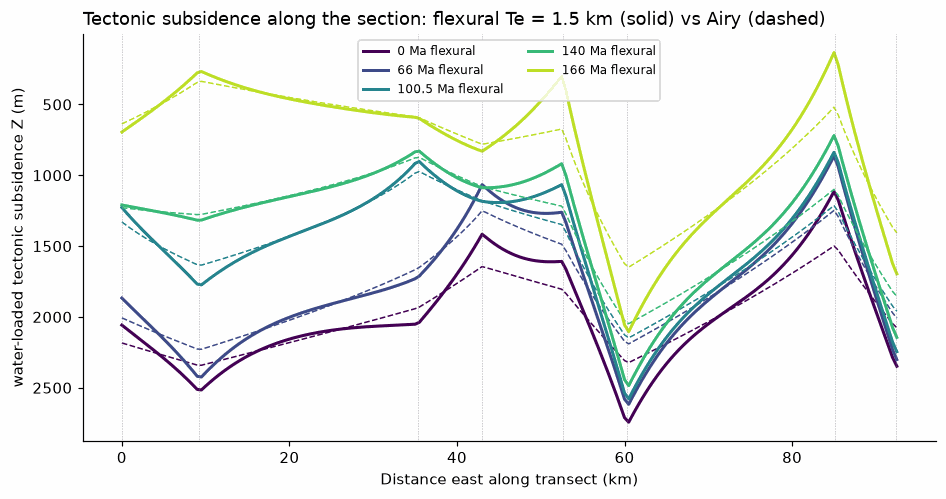

RMS flexural - Airy (m) by Te: {1: np.float64(97.0), 1.5: np.float64(145.0), 3: np.float64(250.0), 10: np.float64(344.0), 25: np.float64(404.0)}


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for a, c in zip([0.0, 66.0, 100.5, 140.0, 166.0], plt.cm.viridis(np.linspace(0, .9, 5))):
    i = int(np.where(np.isclose(rf.ages, a))[0][0])
    ax.plot(xs, rf.Z[i], color=c, lw=2, label=f"{a:g} Ma flexural"); ax.plot(xs, ra.Z[i], color=c, lw=1, ls="--")
for xi in sec.xw / 1e3: ax.axvline(xi, color="grey", lw=.4, ls=":")
ax.invert_yaxis(); ax.set_xlabel("Distance east along transect (km)"); ax.set_ylabel("water-loaded tectonic subsidence Z (m)")
ax.set_title(f"Tectonic subsidence along the section: flexural Te = {TE/1e3:g} km (solid) vs Airy (dashed)", loc="left")
ax.legend(fontsize=8, ncol=2); save(fig, "nb8_tectonic_subsidence_x.png"); plt.show()
print("RMS flexural - Airy (m) by Te:", dict(zip([1, 1.5, 3, 10, 25], flex2d.te_sensitivity(sec, [1e3, 1.5e3, 3e3, 10e3, 25e3]).round(0))))

**Reading.** Z is the subsidence the basement would have had with only water on top, which is the tectonic signal. Solid lines are flexural and dashed lines are Airy. Between the wells they differ most where thickness changes fast (around 40–60 km, the Hegre/Statfjord pinch-outs and the 31/4-3 Triassic depocentre). With T_e = 1.5 km the RMS difference over all ages and positions is ~145 m, rising to ~250 m at 3 km and ~400 m at 25 km. This is Roberts et al.'s (1998) point: Airy over-deepens highs and under-deepens lows.

## Caveats
- **Correlation is well-based, not seismic.** Horizons are joined linearly between 8 wells over ~90 km, with no faults, so the short-wavelength (10–20 km) fault-block loads that matter most for flexure (Roberts et al. 1998, Fig. 7) are under-sampled. Our section is much smoother than theirs.
- **Base is well TD, not basement.** The deepest units (Hegre, Statfjord) are incomplete and differ between wells, so the deepest part of the load is underestimated.
- **Generic inputs.** Lithology fractions, group ages and paleo-water depths come from generic group-level estimates (Sodir formation tops plus literature values), not from measurements in each well. Eustasy is Miller et al. (2020), not Haq et al. (1987) as in Roberts.
- **T_e = 1.5 km is adopted, not fitted.** These data contain no sea-level markers that could calibrate T_e. β is fitted to the generic water depths and has a broad minimum.
- **Pre-rift and syn-rift ages** (> 140 Ma) are only restored in the bathymetric mode (`Restoration.top/base`). Reverse thermal modelling is applied to the post-rift only, as in Roberts et al. (1998).
- **Thermal model.** Instantaneous rifting, uniform pure shear, one β along the line. Erosion and Barents-style uplift are not handled by `flex2d` yet.

## Fault restoration with the flexural cantilever model (Kusznir et al. 1991, 1995)

Up to here the restored sections had no faults. Real rift sections are tilted fault blocks, and Roberts et al. (1998) restore them with **reverse flexural-cantilever modelling** (Kusznir, Marsden & Egan 1991; Kusznir et al. 1995). `flex2d` now implements a simplified version of it.

**Physics of one planar fault.** A normal fault with dip δ cuts the brittle upper crust down to a detachment depth H_d. A slip with vertical component t (throw) drops the hangingwall kinematically: in vertical simple shear it collapses onto the fault plane,

$$v_k(s) = -t\,\mathrm{clip}\!\left(\frac{L-s}{e},0,1\right),\quad s>0,\qquad L = H_d/\tan\delta,\quad e = t/\tan\delta \;(\text{heave}),$$

where s is the distance into the hangingwall. The lowered surface replaces crust (ρ_c = 2800) with syn-rift fill (ρ_f = 2400), so the plate is unloaded by $q = (\rho_c-\rho_f) g\, v_k$ and rebounds flexurally, $D w'''' + (\rho_m-\rho_f) g w = q$. The net displacement is

$$u(x) = v_k(x) - w(x).$$

The footwall is uplifted, and the hangingwall subsides less than t. For T_e → 0 the footwall does not move and the hangingwall subsides $t(\rho_m-\rho_c)/(\rho_m-\rho_f)$ (local isostasy). A stiffer plate spreads the response, giving the classic footwall-uplift / hangingwall-rollover shape.

**Reverse modelling sequence** (`flex2d.restore_faulted`). At each age t_i: (1) strip the units younger than t_i and decompact the rest; (2) apply the flexural rebound from the removed load; (3) remove the McKenzie post-rift thermal subsidence since t_i (β, rift end) and correct for eustasy, as in the earlier sections; (4) for horizons older than the end of faulting, remove the fault slip younger than the horizon. The slips t_j are solved so that the summed cantilever displacements reproduce the observed throws T_j of that horizon at all faults at once (`fault_slips`: A t = T, with A_jk the offset at fault j from a unit slip on fault k). The heave is then closed by moving the hangingwall back toward the footwall.

**Assumption in step 4.** A syn- or pre-rift horizon was deposited with no relief across the fault, so the slip younger than it is its whole present throw. Horizons at or after the end of faulting (base Cretaceous) keep their relief as paleo-bathymetry: these are the sediment-starved fault scarps seen in Roberts et al. (1998) Fig. 4b.

In [8]:
# Line Viking Graben 1 (Roberts et al. 1998 Fig. 4a), digitized; see the notes below the next figure
dv = pd.read_csv(data_path("north_sea", "roberts1998_fig4a_vg1_digitized.csv"))
xg = np.arange(1000.0, 81001.0, 250.0); Iv = lambda c: np.interp(xg, dv.x_km * 1e3, dv[c])
vtops = np.array([Iv(f"top{L}_m") for L in range(1, 11)]); vbase = Iv("base_m"); vbot = np.vstack([vtops[1:], vbase[None]])
VUNITS = ["Pliocene-Recent", "Miocene", "Eocene-Oligocene", "Palaeocene", "Upper Cretaceous", "Lower Cretaceous",
          "Kimmeridgian-Ryazanian (Draupne)", "Callovian-Oxfordian (Heather)", "Bajocian-Bathonian (Brent)", "Triassic-Lower Jurassic"]
VAGES = [0, 5.3, 23.0, 56.0, 66.0, 100.5, 140.0, 157.3, 166.1, 170.3]
VLITH = [{"shale": 1}] * 4 + [{"chalk": 1}, {"shale": 1}, {"shale": 1}, {"shale": 1}, {"sandstone": 1}, {"shaly_sandstone": 1}]
VCOL = ["#f08068", "#60a0c0", "#f8f000", "#b840a8", "#00a050", "#e81820", "#8070c0", "#908888", "#60a0c0", "#f8f000"]
vsec = flex2d.section_from_horizons(xg, vtops, vbase, VUNITS, VAGES, VAGES[1:] + [252.0], VLITH, vtops[0])
vfaults = [flex2d.fault_at(xg, vtops, x0 * 1e3, down=1, win=1500.0, dip=45.0, label=l,
                           source="digitized position/throw, Roberts et al. 1998 Fig. 4a; dip assumed")
           for x0, l in zip([6.75, 19.0, 29.25, 44.25, 65.75], ["margin", "Heather|Pelican", "Pelican|Hutton", "Hutton|Brent", "Brent|Gullfaks"])]
pd.DataFrame({f.label: f.throw for f in vfaults}, index=[f"top {u}" for u in VUNITS]).round(0)

,margin,Heather|Pelican,Pelican|Hutton,Hutton|Brent,Brent|Gullfaks
top Pliocene-Recent,0.0,11.0,0.0,0.0,0.0
top Miocene,23.0,34.0,83.0,0.0,34.0
top Eocene-Oligocene,34.0,46.0,57.0,0.0,31.0
top Palaeocene,163.0,63.0,11.0,34.0,23.0
top Upper Cretaceous,306.0,34.0,46.0,34.0,23.0
top Lower Cretaceous,900.0,183.0,289.0,217.0,271.0
top Kimmeridgian-Ryazanian (Draupne),1151.0,406.0,651.0,240.0,460.0
top Callovian-Oxfordian (Heather),1437.0,606.0,800.0,357.0,746.0
top Bajocian-Bathonian (Brent),1743.0,811.0,1040.0,646.0,1157.0
top Triassic-Lower Jurassic,1880.0,880.0,1109.0,731.0,1500.0


saved image/nb8_vg1_fault_planes.png


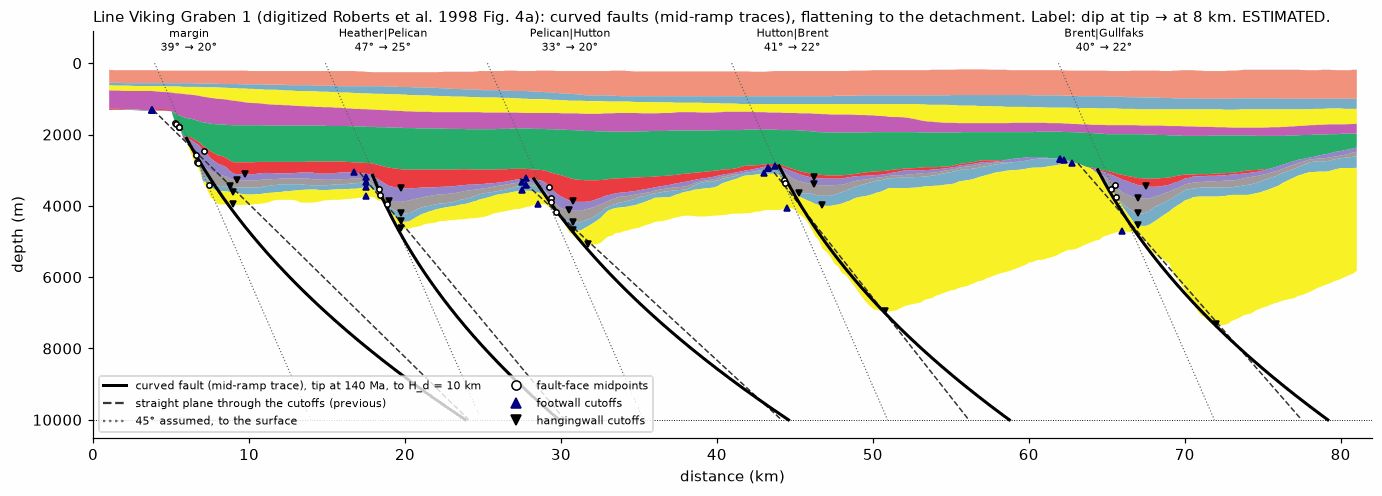

,fault,x0_km,dip_tip,dip_4km,dip_8km,dip_effective,dip_straight_plane,top_tip_m,rms_x_m
0,margin,6.2,38.9,30.8,19.6,34.9,23.2,2108.1,289.0
1,Heather|Pelican,18.6,46.8,42.3,25.4,42.9,27.8,3145.7,172.5
2,Pelican|Hutton,30.6,32.7,30.9,19.6,30.1,22.0,3244.3,292.5
3,Hutton|Brent,44.8,40.7,35.6,21.8,31.4,29.1,2880.1,223.7
4,Brent|Gullfaks,64.8,39.8,35.1,21.7,30.1,26.6,2990.7,293.3


In [9]:
# Present-day section with CURVED faults (notebook 9, faults.faults_from_curves): fitted through the steep fault-face
# midpoints of the syn-rift horizons, the footwall/hangingwall cutoffs incl. top and base Triassic (yellow block edges),
# flattening with depth toward the detachment; upper tip at 140 Ma (top Kimmeridgian-Ryazanian, base of the post-rift:
# the faults do not cut the Cretaceous or younger units). Default trace_anchor='midramp': the trace crosses top Triassic in the
# middle of the drawn fault ramp (option 'footwall_crest'; or your own faults: F.load_faults("user", ...)). Straight cutoff planes (previous version) dashed for comparison.
from pybasinsubs import faults as F
det_raw, _ = F.detect_faults_from_horizons(xg, vtops)
vcut = F.faults_from_cutoffs(det_raw, xg, vtops, vbase, tip_unit=6)
vcurve = F.faults_from_curves(det_raw, xg, vtops, vbase, tip_unit=6, Hd=10e3)
for f, v in zip(vcurve, vfaults): f.label = v.label
fig, ax = plt.subplots(figsize=(15, 4.8))
for k in range(len(vtops)):
    ax.fill_between(xg / 1e3, vtops[k], vtops[k + 1] if k + 1 < len(vtops) else vbase, color=VCOL[k], lw=0, alpha=.85)
FF.plot_fault_planes(ax, vfaults, 10e3, "planar", xg, vtops, z_top=0.0, labels=False, color="0.4", lw=.8, ls=":")
FF.plot_fault_planes(ax, vcut, 10e3, "planar", xg, vtops, labels=False, color="0.2", lw=1.0, ls="--")
FF.plot_fault_planes(ax, vcurve, 10e3, "planar", xg, vtops, labels=False, color="k", lw=2.0)
for f, g in zip(vcurve, det_raw):
    t = f.cutoffs["table"]; ax.plot(t.x_fw / 1e3, t.z_fw, "^", color="navy", ms=4); ax.plot(t.x_hw / 1e3, t.z_hw, "kv", ms=4)
    s = np.asarray(g.stick); ax.plot(s[:, 0] / 1e3, s[:, 1], "o", color="w", mec="k", ms=3.5)
    ax.text(f.x0 / 1e3, -350, f"{f.label}\n{f.dip_at(f.z_tip):.0f}° → {f.dip_at(8e3):.0f}°", fontsize=7.5, ha="center")
ax.axhline(10e3, color="k", lw=.6, ls=":")
ax.plot([], [], "k-", lw=2, label="curved fault (mid-ramp trace), tip at 140 Ma, to H_d = 10 km")
ax.plot([], [], "--", color="0.2", label="straight plane through the cutoffs (previous)"); ax.plot([], [], ":", color="0.4", label="45° assumed, to the surface")
ax.plot([], [], "o", color="w", mec="k", label="fault-face midpoints"); ax.plot([], [], "^", color="navy", label="footwall cutoffs"); ax.plot([], [], "kv", label="hangingwall cutoffs")
ax.set_ylim(10.5e3, -900); ax.set_xlim(0, 82); ax.set_xlabel("distance (km)"); ax.set_ylabel("depth (m)"); ax.legend(fontsize=7.5, loc="lower left", ncol=2)
ax.set_title("Line Viking Graben 1 (digitized Roberts et al. 1998 Fig. 4a): curved faults (mid-ramp traces), flattening to the detachment. Label: dip at tip → at 8 km. ESTIMATED.", loc="left", fontsize=10)
save(fig, "nb8_vg1_fault_planes.png"); plt.show()
pd.DataFrame([dict(fault=f.label, x0_km=f.x0 / 1e3, dip_tip=f.dip_at(f.z_tip), dip_4km=f.dip_at(4e3), dip_8km=f.dip_at(8e3),
                   dip_effective=f.dip, dip_straight_plane=p.dip, top_tip_m=f.z_tip, rms_x_m=f.curve_params["rms_x"])
              for f, p in zip(vcurve, vcut)]).round(1)


saved image/nb8_fault_cantilever_concept.png


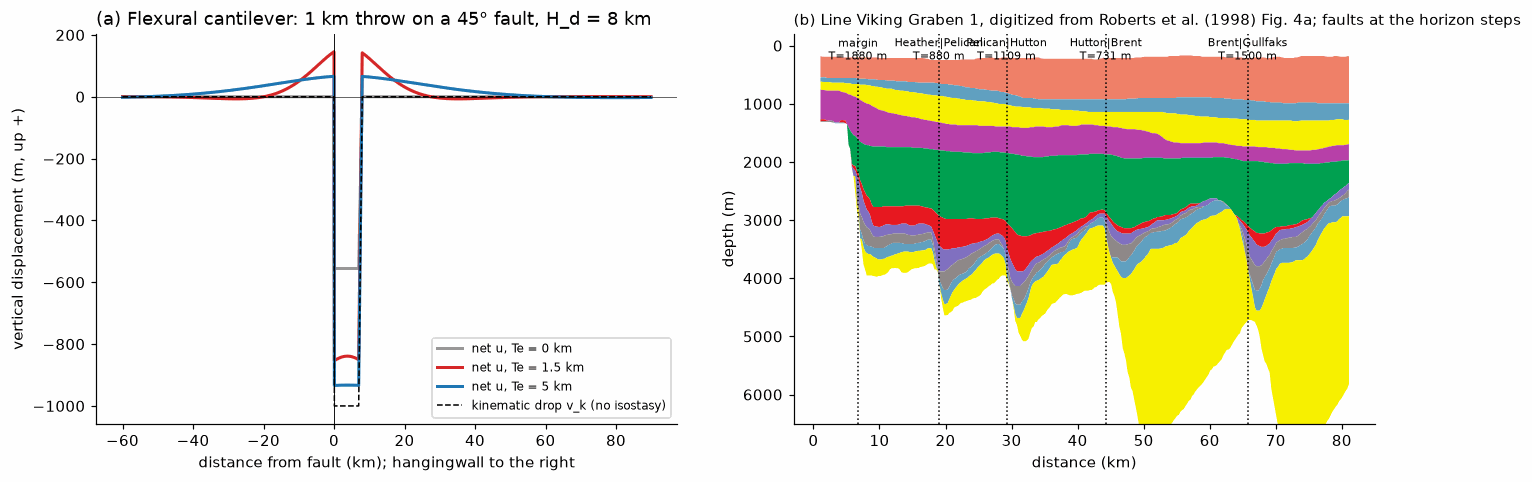

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
xs = np.arange(-60e3, 90e3, 100.0)
for Te_, c in [(0.0, "0.6"), (1500.0, "C3"), (5000.0, "C0")]:
    u, vk, w = flex2d.cantilever_displacement(xs, 0.0, 1000.0, 45.0, 1, Te_, Hd=8e3, rho_fill=2400.0)
    ax[0].plot(xs/1e3, u, color=c, lw=2, label=f"net u, Te = {Te_/1e3:g} km")
ax[0].plot(xs/1e3, vk, "k--", lw=1, label="kinematic drop v_k (no isostasy)")
ax[0].axvline(0, color="k", lw=.6); ax[0].axhline(0, color="k", lw=.4)
ax[0].set_xlabel("distance from fault (km); hangingwall to the right"); ax[0].set_ylabel("vertical displacement (m, up +)")
ax[0].set_title("(a) Flexural cantilever: 1 km throw on a 45° fault, H_d = 8 km", loc="left"); ax[0].legend(fontsize=8)
for k in range(10):
    ax[1].fill_between(xg/1e3, vtops[k], vbot[k], color=VCOL[k], lw=0)
for f in vfaults:
    ax[1].axvline(f.x0/1e3, color="k", ls=":", lw=1)
    ax[1].text(f.x0/1e3, 300, f"{f.label}\nT={f.throw[9]:.0f} m", fontsize=7, ha="center", va="bottom")
ax[1].set_ylim(6500, -200); ax[1].set_xlabel("distance (km)"); ax[1].set_ylabel("depth (m)")
ax[1].set_title("(b) Line Viking Graben 1, digitized from Roberts et al. (1998) Fig. 4a; faults at the horizon steps", loc="left", fontsize=10)
save(fig, "nb8_fault_cantilever_concept.png"); plt.show()

**Reading (a).** The dashed line is the pure kinematic drop of the collapsing hangingwall, a box of width L = H_d/tan δ = 8 km. With local isostasy (grey) the footwall does not move and the hangingwall keeps 56 % of the drop, (ρ_m−ρ_c)/(ρ_m−ρ_f). A stiffer plate (red 1.5 km, blue 5 km) cannot compensate an 8 km wide load locally. So more of the drop stays in the hangingwall, and the rebound is shared out as **footwall uplift** and a bulge beyond the box. The net offset at the fault therefore depends on T_e, which is why `fault_slips` solves for the slip that reproduces the *observed* throw.

**(b) Data source and what is measured vs assumed.** The present-day section of line Viking Graben 1 (East Shetland Basin; Roberts et al. 1998, Fig. 4a, p. 331, after Roberts et al. 1993b) was **digitized** from the publisher PDF (badleys.co.uk) by colour segmentation of the 10 layers at 600 dpi, using the figure's 0–80 km and 0/5 km scale ticks. It was then median-filtered to remove the figure's vertical hairlines and text, and saved as `pybasinsubs/example_data/north_sea/roberts1998_fig4a_vg1_digitized.csv`. Depth precision is about ±25 m (one pixel is 11 m) plus line-width effects.
- **Measured from the figure:** horizon depths; fault positions (the five steps of the base Brent / top Triassic horizon at 6.75, 19.0, 29.25, 44.25 and 65.75 km, all down to the east); and the throws of every horizon read 1.5 km either side of each fault.
- **Assumed (not in the figure):** fault dip 45°; detachment depth H_d = 8 km; syn-rift fill density 2400 kg/m³; lithologies (shale; chalk for the Upper Cretaceous; sandstone for the Brent; shaly sandstone for the Triassic–Lower Jurassic); layer ages (ICS ages of the stage names in the figure legend); no eustasy; no Triassic rift. The figure has 4× vertical exaggeration, and the steepest digitized fault faces are 31–50° at true scale (smoothed by the drawing and the digitizing), so 45° is consistent with them. The base of layer 10 in the figure is the drawing's lower limit, not a geological horizon.

saved image/nb8_vg1_fault_restoration.png


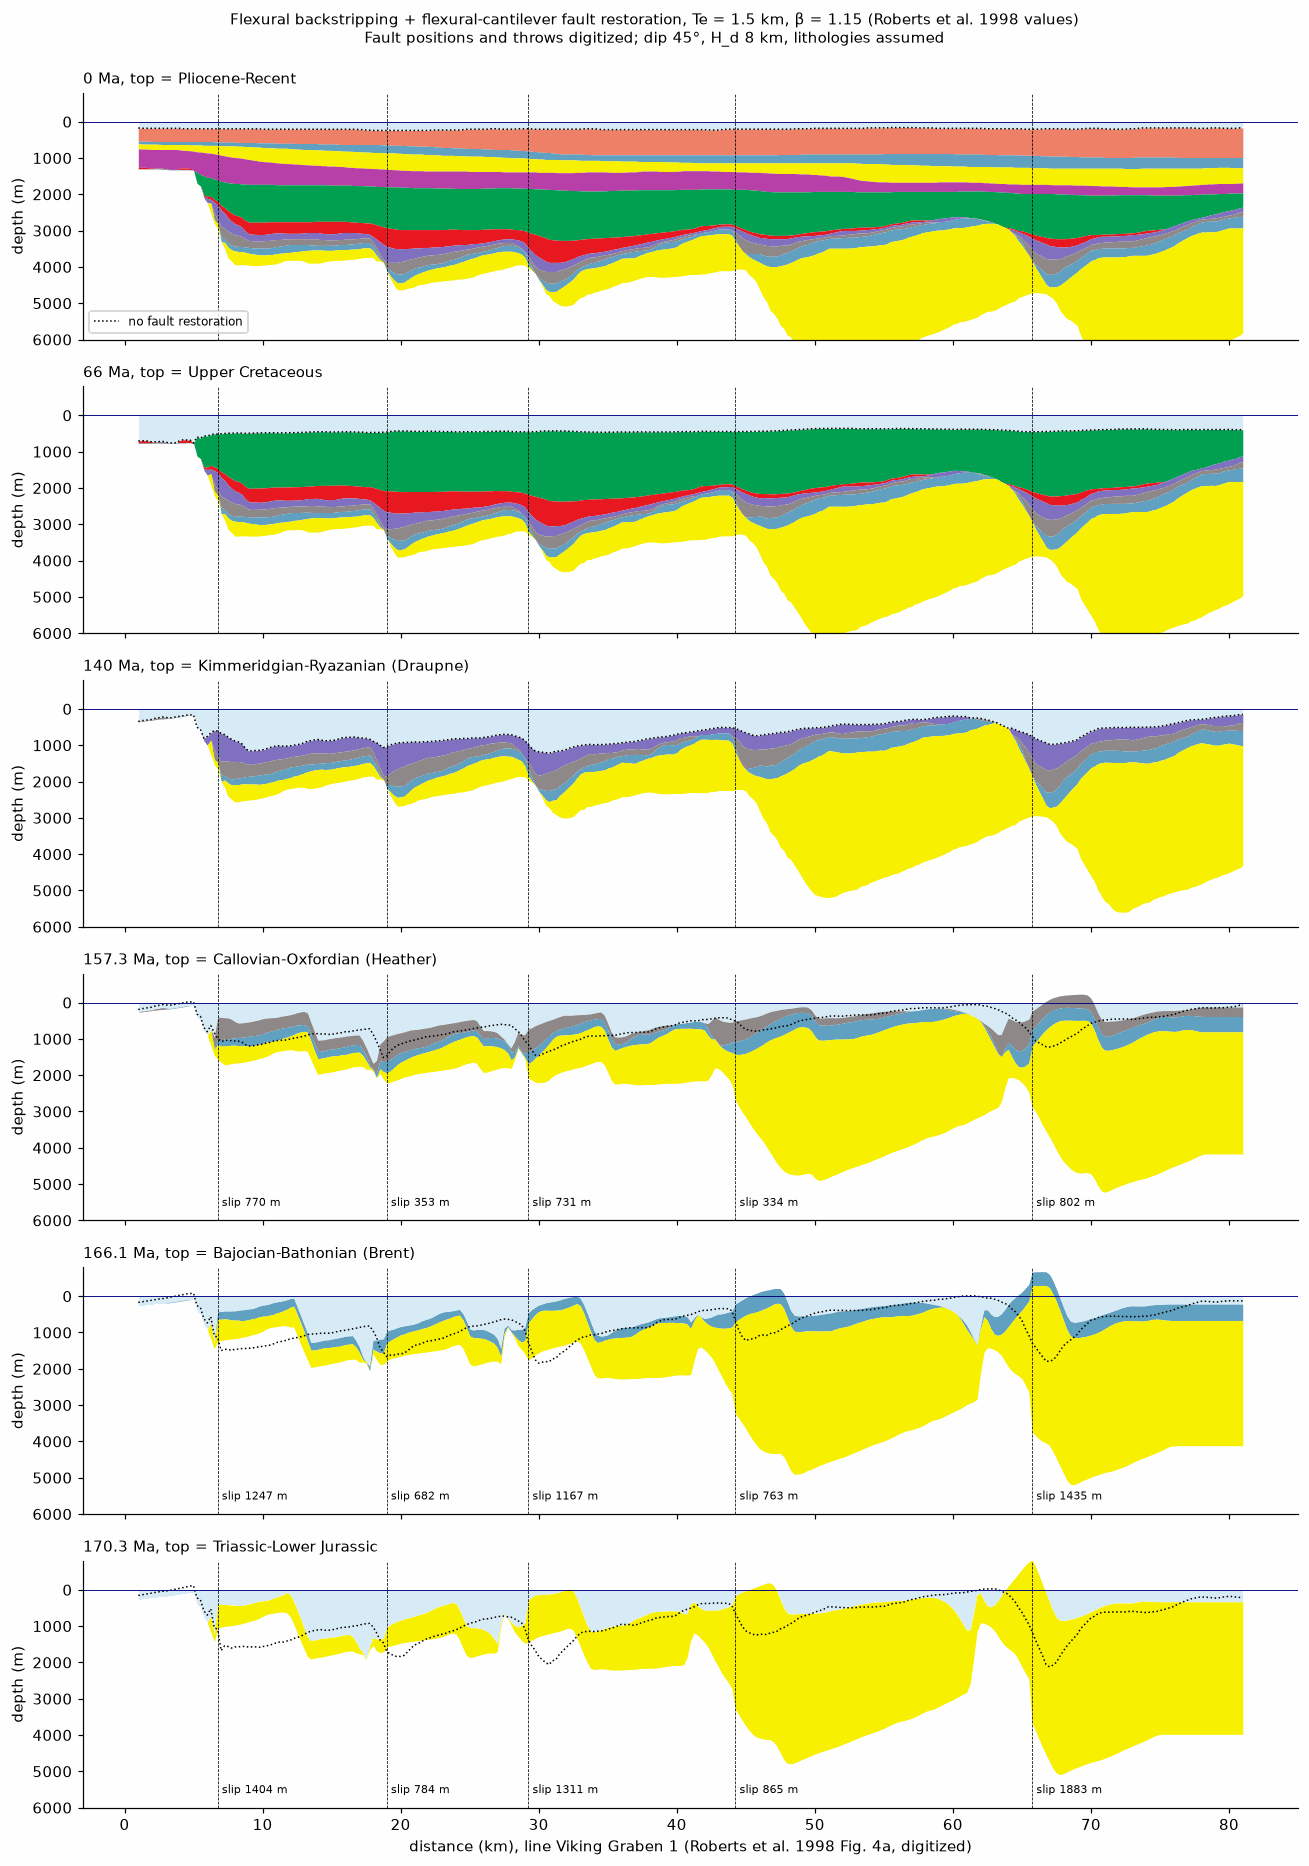

Brent crest depth at 140 Ma: Te=1.5 km 197 m, Airy 383 m
std of restored top surface at 170.3 Ma (top Triassic-L. Jurassic): no fault restoration 540 m, with 422 m; present-day 687 m


In [11]:
vr = flex2d.restore_faulted(vsec, vfaults, Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0, Hd=8e3)
vr0 = flex2d.restore_faulted(vsec, [], Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0, Hd=8e3)
show = [0, 4, 6, 7, 8, 9]
fig, axs = plt.subplots(len(show), 1, figsize=(12, 17), sharex=True)
for a_, i in zip(axs, show):
    a_.fill_between(xg/1e3, 0, vr["seafloor"][i], color="#d8ecf7", lw=0)
    for k in range(i, 10):
        a_.fill_between(xg/1e3, vr["top"][i][k], vr["base"][i][k], color=VCOL[k], lw=0)
    a_.plot(xg/1e3, vr0["top"][i][i], "k:", lw=1, label="no fault restoration")
    for f, sl in zip(vfaults, vr["slip"][i]):
        a_.axvline(f.x0/1e3, color="k", lw=.5, ls="--")
        if sl > 0: a_.text(f.x0/1e3 + .3, 5600, f"slip {sl:.0f} m", fontsize=7)
    a_.axhline(0, color="navy", lw=.6); a_.set_ylim(6000, -800); a_.set_ylabel("depth (m)")
    a_.set_title(f"{vr['ages'][i]:g} Ma, top = {vsec.units[i]}", loc="left", fontsize=10)
axs[0].legend(fontsize=8, loc="lower left")
axs[-1].set_xlabel("distance (km), line Viking Graben 1 (Roberts et al. 1998 Fig. 4a, digitized)")
fig.suptitle("Flexural backstripping + flexural-cantilever fault restoration, Te = 1.5 km, β = 1.15 (Roberts et al. 1998 values)\n"
             "Fault positions and throws digitized; dip 45°, H_d 8 km, lithologies assumed", y=0.995, fontsize=10)
fig.tight_layout(); save(fig, "nb8_vg1_fault_restoration.png"); plt.show()
sf = vr["seafloor"][6]; m = (xg > 55e3) & (xg < 66e3)
vra = flex2d.restore_faulted(vsec, vfaults, Te=0.0, beta=1.15, Hd=8e3)
print("Brent crest depth at 140 Ma: Te=1.5 km %.0f m, Airy %.0f m" % (sf[m].min(), vra["seafloor"][6][m].min()))
print("std of restored top surface at 170.3 Ma (top Triassic-L. Jurassic): no fault restoration %.0f m, with %.0f m; present-day %.0f m"
      % (vr0["top"][9][9].std(), vr["top"][9][9].std(), vtops[9].std()))

**Reading.**
- **0–66 Ma.** Stripping the Cenozoic and Upper Cretaceous only unloads and decompacts the section, and removes post-rift thermal subsidence.
- **140 Ma (base Cretaceous).** The fault blocks reappear as sea-floor topography. With T_e = 1.5 km the Brent crest restores to about 200 m water depth, versus about 383 m with Airy isostasy. Roberts et al. (1998, Fig. 4b vs 4c, p. 331) describe the same contrast: with T_e = 1.5 km, β = 1.15 the Brent crest returns to about sea level, while with Airy isostasy no part of the section does. Our numbers are shallower-than-Airy but not at sea level. Likely reasons: our lithologies are assumed, we include no Haq et al. (1987) eustasy, no Triassic thermal subsidence (they include a 250 Ma, β = 1.2 event), and our ages are approximate. So this is a qualitative check, not a reproduction.
- **157–170 Ma (syn-rift).** The fault slips are removed. The fault offsets are closed, and the spread of the top Triassic–Lower Jurassic surface drops from about 540 m (dotted, no fault restoration) to about 420 m. What remains is mainly the **tilt of the blocks** (their dip slopes). **⚠ Artefacts (not geology):** spikes at the digitized fault faces, steps where each 8 km kinematic box ends, and footwall/hangingwall overlaps after the heave is closed (for example around 7–12 km and 66–70 km, where restored blocks rise above sea level). Treat the syn-rift panels as a demonstration of the method, not a geological reconstruction. With planar faults and T_e = 1.5 km the cantilever model generates little rotation. A full Kusznir-style model would also include the β-profile pure-shear lower-crust thinning and syn-rift thermal effects (Roberts et al. 1998 Fig. 4e uses such a forward β-profile). These are not implemented.

**Alignment with our well transect.** Line Viking Graben 1 crosses the East Shetland Basin to Gullfaks (UK/Norway, about 61°N, roughly 1–2.3°E). Our 8-well Sodir transect runs at about 60.5–60.7°N, 2.0–3.7°E, so it is **50–80 km to the south and east**. It crosses the Viking Graben axis and the Oseberg/Brage area, not these fault blocks. The fault restoration is therefore demonstrated on the published section and **not** applied to our well transect: its wells are 12 km apart, mostly on highs, and constrain neither fault positions nor throws.

## Slip derived from growth strata: listric/inclined-shear vs rigid domino rotation

The cantilever restoration above uses one throw per fault and horizon. Here the slip of **each time step** is derived from (i) the fault geometry and (ii) the **decompacted thickness of the unit stripped at that step, which varies across x**. This is the growth-wedge principle: while a syn-rift unit is deposited, the fault creates extra accommodation in its hangingwall, and that unit's thickness records it. Two mechanisms are implemented as options in `flex2d.restore_kinematic` and compared.

**Target for every step.** When unit j−1 is stripped (step j), each hangingwall block of fault k gets the accommodation profile

$$D_k(x) = h_{j-1}(x) - h_{j-1}(x_{FW}),\qquad x \in \text{block } k,$$

where h is the decompacted thickness at step j−1 (in the coordinates already restored) and x_FW is the footwall cutoff, 1.5 km on the footwall side of the fault. At the first syn-rift step (the stripped unit is the Kimmeridgian–Ryazanian rift climax), the paleo-bathymetric relief left at the base Cretaceous is added to D. Assumption: that relief was created in the rift-climax interval (sediment-starved hangingwalls).

**(A) Listric fault + simple shear** (Verrall 1981; White, Jackson & McKenzie 1986; Kusznir & Egan 1989). The fault depth decays exponentially from a near-surface dip δ₀ to a detachment at H_d:

$$f(x) = z_0 + (H_d - z_0)\left[1-\exp\!\left(-\frac{s\tan\delta_0}{H_d-z_0}\right)\right],\qquad s = \pm(x-x_0) > 0.$$

For heave e, a hangingwall point moves along a shear line at angle α from horizontal (antithetic, dipping toward the fault). **Only inclined shear is offered** (20° ≤ α < 89°, default 65°). Vertical shear is excluded because it is not a geologically valid hangingwall deformation for these faults; typical antithetic shear angles in published restorations are about 60–70° (White et al. 1986; Kusznir & Egan 1989). The base of that shear line stays on the fault, which gives a vertical displacement varying with x:

$$s(x) = f(x_b) - f\big(x_b - (e - s\cot\alpha)\big),\qquad x_b = x - (f(x_b)-z)\cot\alpha .$$

For a planar fault of slope t this gives a constant s = t·e/(1 + t·cot α), which is a unit test. Near the fault, where f is steep, s is large; it decays toward the detachment, producing the rollover. At each step the heave e_k of every fault is fitted (least squares) so that s(x) matches D_k(x). Every horizon below is then restored along its own shear lines, and the restored pieces are recombined: the footwall wins overlaps, and gaps are interpolated and measured.

**(B) Rigid domino blocks on planar faults.** Each hangingwall block is rigid. Fitting D_k(x) ≈ a + b·s over the block gives the rotation φ = atan(−b) about the footwall cutoff, the vertical translation a, and the heave a/tan δ:

$$x' = x_p + \Delta x\cos\varphi - \Delta z\sin\varphi - \text{heave},\qquad z' = z_p + \Delta x\sin\varphi + \Delta z\cos\varphi - a .$$

Both mechanisms run inside the same sequence as before: strip, decompact, flexural unloading (T_e = 1.5 km), reverse post-rift thermal (β = 1.15) and eustasy. Then, for every syn-rift step, the fault restorations of all younger steps are applied in order (youngest first). Unlike the cantilever, the isostatic response to the fault slip itself is **not** included in (A) or (B).

**Estimated, not measured.** Listric shapes are fitted to the digitized fault faces of the present-day top Triassic–Lower Jurassic, between cutoffs 1.5 km either side of each fault. With a 1–2 km high face drawn at 4× vertical exaggeration, the fitted near-surface dips are poorly constrained (search limited to 30–75°). H_d = 10 km is **assumed**. Domino faults use the 45° planar dip. All fits are labelled *estimated* in the figures.

saved image/nb8_kinematic_concept.png


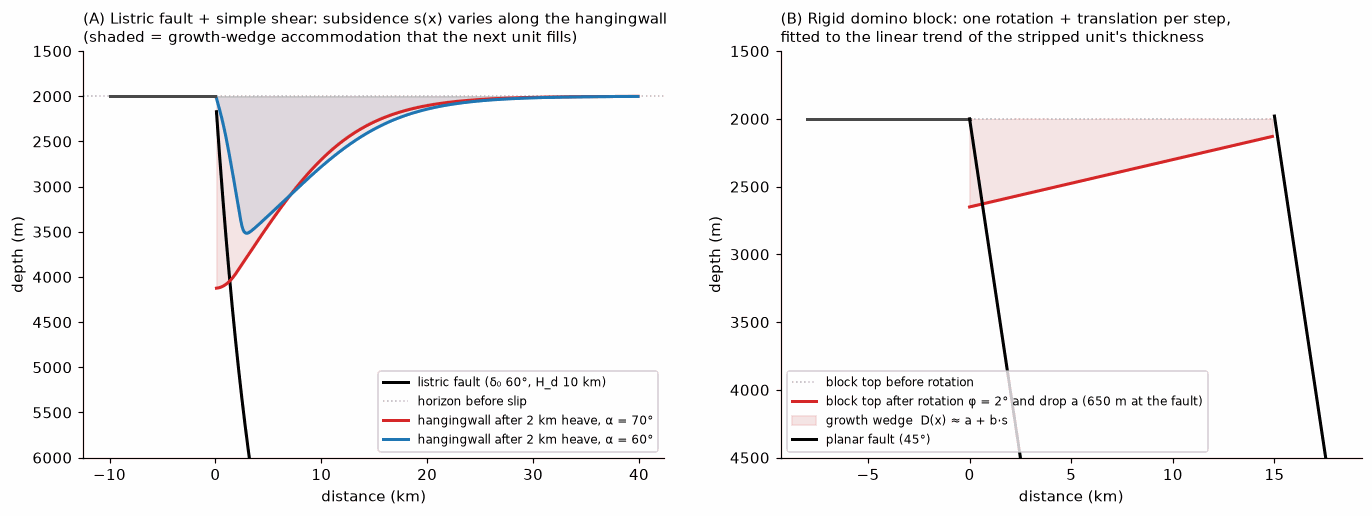

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
xs = np.arange(-10e3, 40e3, 100.0); fx = lambda q: flex2d.listric_depth(q, 0.0, 2000.0, 60.0, 10e3, 1)
ax[0].plot(xs/1e3, np.where(xs > 0, fx(xs), np.nan), "k", lw=2, label="listric fault (δ₀ 60°, H_d 10 km)")
hw = xs > 0; ax[0].axhline(2000, color="0.7", lw=1, ls=":", label="horizon before slip")
for al, c in [(70.0, "C3"), (60.0, "C0")]:
    _, s = flex2d._shear_subsidence(xs[hw], np.full(hw.sum(), 2000.0), fx, 2000.0, 1, al)
    ax[0].plot(xs[hw]/1e3, 2000 + s, color=c, lw=2, label=f"hangingwall after 2 km heave, α = {al:g}°")
    ax[0].fill_between(xs[hw]/1e3, 2000, 2000 + s, color=c, alpha=.12)
ax[0].plot(xs[~hw]/1e3, np.full((~hw).sum(), 2000.0), "0.3", lw=2)
ax[0].set_ylim(6000, 1500); ax[0].set_xlabel("distance (km)"); ax[0].set_ylabel("depth (m)")
ax[0].set_title("(A) Listric fault + simple shear: subsidence s(x) varies along the hangingwall\n(shaded = growth-wedge accommodation that the next unit fills)", loc="left", fontsize=10)
ax[0].legend(fontsize=8, loc="lower right")
# domino
xb = np.arange(0, 15e3, 100.0); phi = np.radians(2.0)
ax[1].plot(np.r_[-8e3, 0]/1e3, [2000, 2000], "0.3", lw=2)
ax[1].plot(xb/1e3, 2000 + 0*xb, color="0.7", ls=":", lw=1, label="block top before rotation")
blk = 2000 + 650 - np.tan(phi) * xb
ax[1].plot(xb/1e3, blk, color="C3", lw=2, label="block top after rotation φ = 2° and drop a (650 m at the fault)")
ax[1].fill_between(xb/1e3, 2000, blk, color="C3", alpha=.12, label="growth wedge  D(x) ≈ a + b·s")
ax[1].plot([0, 3.0], [2000, 2000 + 3000*np.tan(np.radians(45))], "k", lw=2, label="planar fault (45°)")
ax[1].plot([15, 18.0], [blk[-1] - 150, blk[-1] - 150 + 3000*np.tan(np.radians(45))], "k", lw=2)
ax[1].set_ylim(4500, 1500); ax[1].set_xlabel("distance (km)"); ax[1].set_ylabel("depth (m)")
ax[1].set_title("(B) Rigid domino block: one rotation + translation per step,\nfitted to the linear trend of the stripped unit's thickness", loc="left", fontsize=10)
ax[1].legend(fontsize=8, loc="lower left")
save(fig, "nb8_kinematic_concept.png"); plt.show()

In [13]:
METHODS = {"no fault restoration": None, "planar cantilever (previous)": "cant",
           "(A) listric, inclined shear 65° (default)": ("listric", 65.0), "(A) listric, inclined shear 60°": ("listric", 60.0),
           "(B) rigid domino": ("domino", 90.0)}
RES = {}
for name, m in METHODS.items():
    if m is None:
        RES[name] = flex2d.restore_faulted(vsec, [], Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0)
    elif m == "cant":
        RES[name] = vr
    else:
        RES[name] = flex2d.restore_kinematic(vsec, vfaults, method=m[0], alpha=m[1], Te=1500.0, beta=1.15,
                                             rift_end_Ma=155.0, fault_end_Ma=140.0, Hd=10e3)
print("estimated listric near-surface dips (deg):", np.round(RES["(A) listric, inclined shear 65° (default)"]["listric_dips"]))
A0 = flex2d.layer_areas(RES["no fault restoration"], 9)[9]
rows = []
for name, r in RES.items():
    mt = flex2d.restoration_metrics(r, 9, xg, vfaults)
    mt157 = flex2d.restoration_metrics(r, 7, xg, vfaults)
    rows.append({"method": name, "std 170 Ma (m)": mt["std"], "P95-P5 relief 170 Ma (m)": mt["relief_p95_p5"],
                 "max relief 170 Ma (m)": mt["max_relief"], "mean |fault offset| 170 Ma (m)": mt["mean_fault_offset"],
                 "std 157 Ma (m)": mt157["std"], "roughness (m)": mt["roughness"],
                 "area change layer 10 (%)": 100 * (flex2d.layer_areas(r, 9)[9] / A0 - 1),
                 "overlap 170 Ma (km)": r.get("overlap_m", np.zeros(10))[9] / 1e3, "gap 170 Ma (km)": r.get("gap_m", np.zeros(10))[9] / 1e3})
MET = pd.DataFrame(rows).set_index("method"); MET.round(1)

estimated listric near-surface dips (deg): [41. 30. 30. 30. 31.]


,std 170 Ma (m),P95-P5 relief 170 Ma (m),max relief 170 Ma (m),mean |fault offset| 170 Ma (m),std 157 Ma (m),roughness (m),area change layer 10 (%),overlap 170 Ma (km),gap 170 Ma (km)
method,,,,,,,,,
no fault restoration,536.6,1756.3,2236.6,1235.7,365.5,85.6,0.0,0.0,0.0
planar cantilever (previous),425.4,1402.9,2742.3,650.4,313.6,144.2,7.2,0.0,0.0
"(A) listric, inclined shear 65° (default)",466.4,1592.1,2203.4,933.8,287.4,154.4,10.5,2.8,5.2
"(A) listric, inclined shear 60°",466.5,1600.7,2212.8,920.0,286.1,152.9,11.0,2.5,5.5
(B) rigid domino,396.7,1135.7,1830.8,489.7,240.1,148.9,3.0,1.5,5.2


saved image/nb8_fault_methods_comparison.png


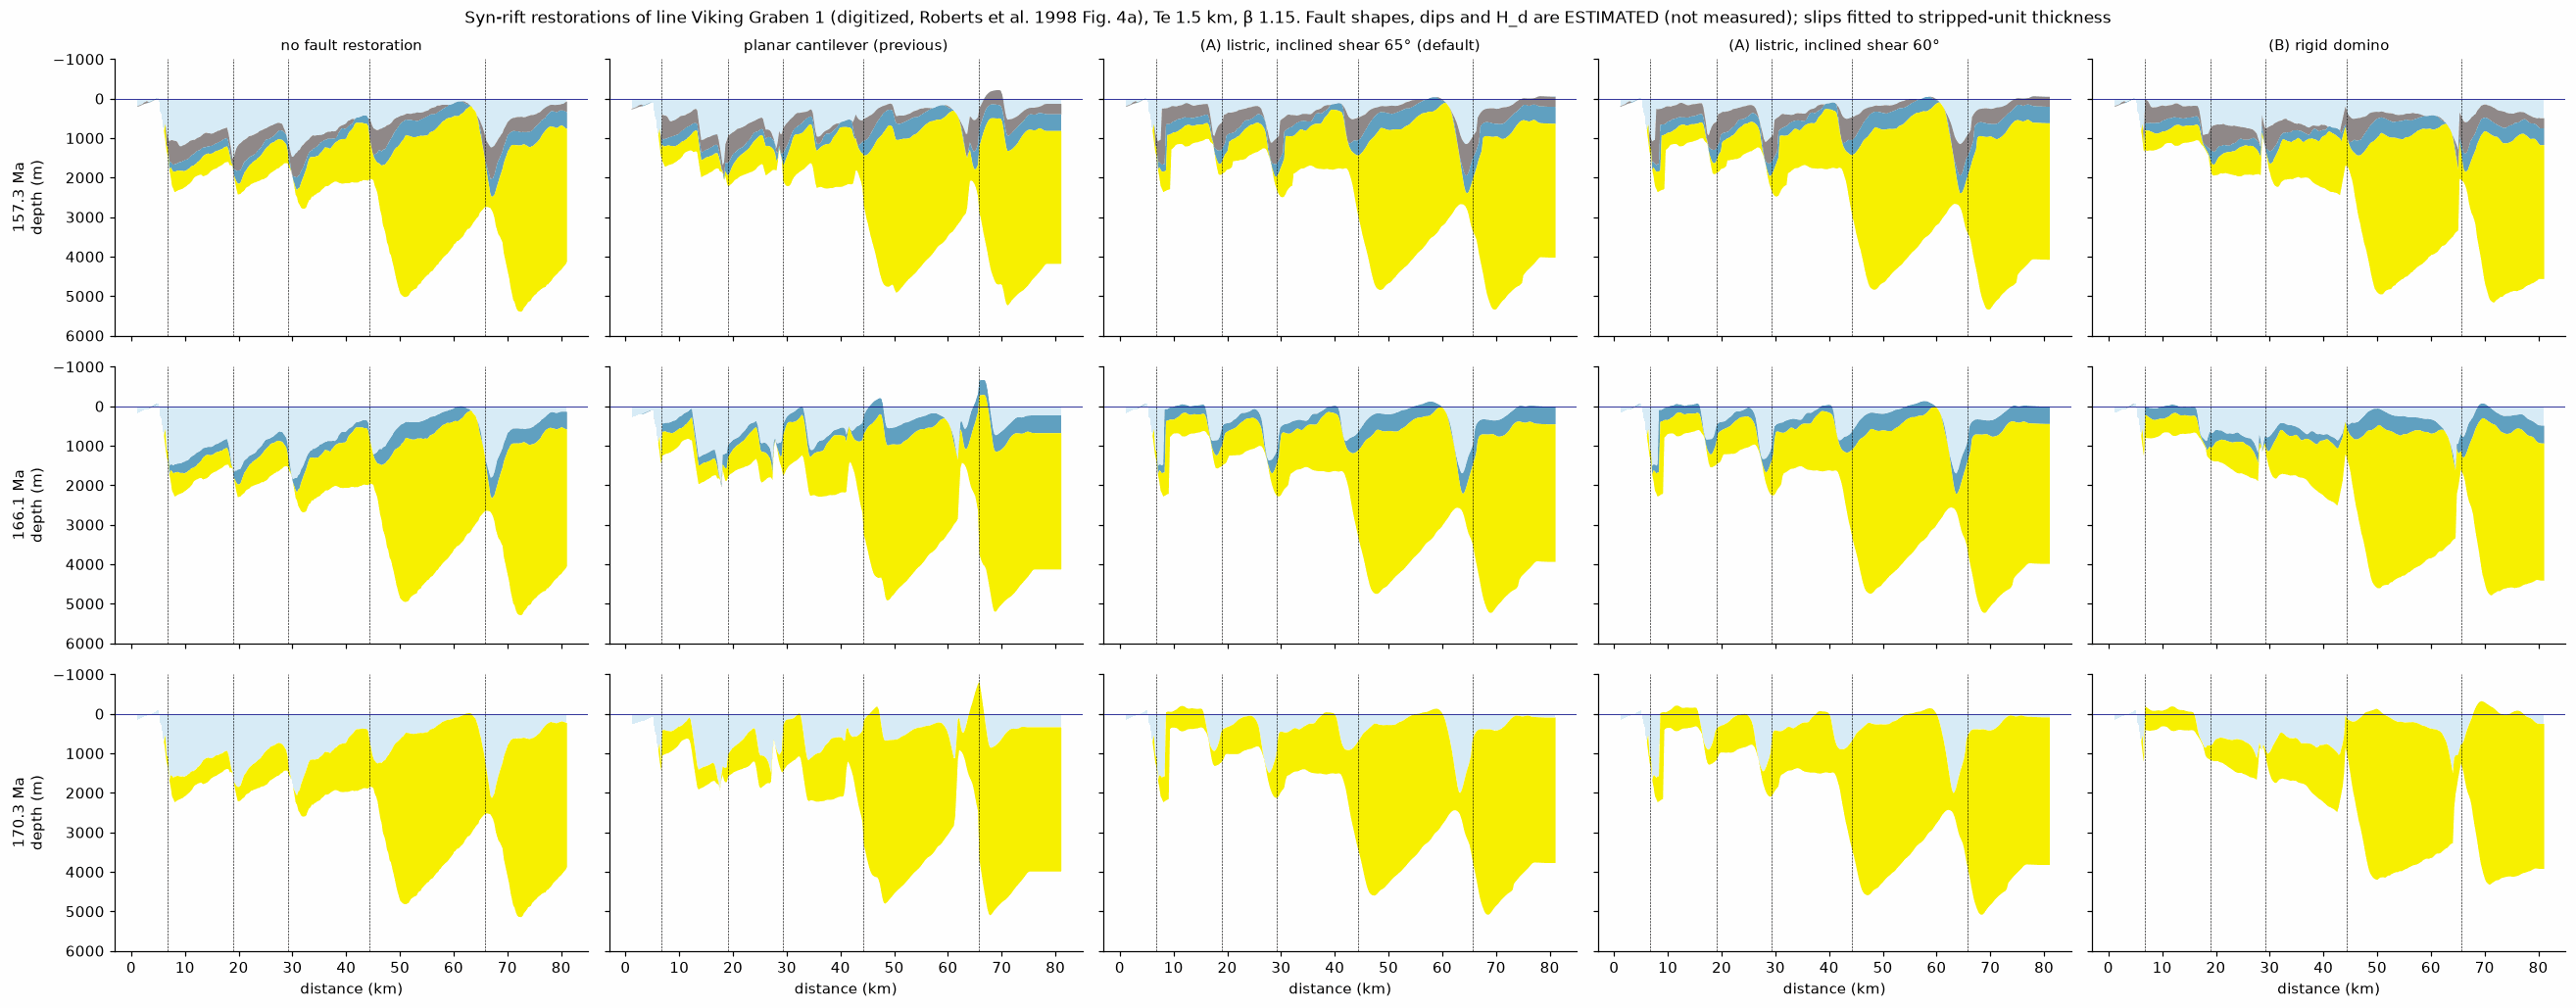

In [14]:
show = [7, 8, 9]; names = list(RES)
fig, axs = plt.subplots(len(show), len(names), figsize=(24, 9.5), sharex=True, sharey=True)
for c, nm in enumerate(names):
    r = RES[nm]
    for rr, i in enumerate(show):
        a_ = axs[rr, c]
        a_.fill_between(xg/1e3, 0, r["seafloor"][i], color="#d8ecf7", lw=0)
        for k in range(i, 10):
            a_.fill_between(xg/1e3, r["top"][i][k], r["base"][i][k], color=VCOL[k], lw=0)
        for f in vfaults: a_.axvline(f.x0/1e3, color="k", lw=.4, ls="--")
        a_.axhline(0, color="navy", lw=.5); a_.set_ylim(6000, -1000)
        if rr == 0: a_.set_title(nm, fontsize=10)
        if c == 0: a_.set_ylabel(f"{vr['ages'][i]:g} Ma\ndepth (m)")
for a_ in axs[-1]: a_.set_xlabel("distance (km)")
fig.suptitle("Syn-rift restorations of line Viking Graben 1 (digitized, Roberts et al. 1998 Fig. 4a), Te 1.5 km, β 1.15. "
             "Fault shapes, dips and H_d are ESTIMATED (not measured); slips fitted to stripped-unit thickness", fontsize=11)
fig.tight_layout(); save(fig, "nb8_fault_methods_comparison.png"); plt.show()

saved image/nb8_fault_methods_metrics.png


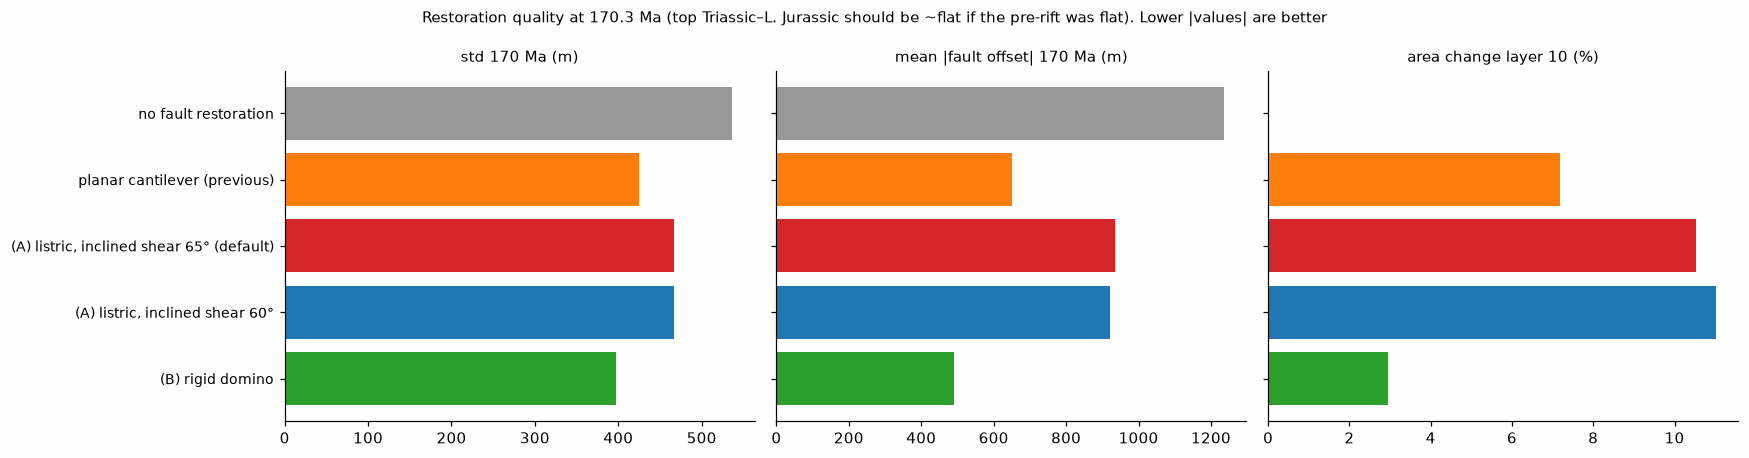

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cols = ["0.6", "C1", "C3", "C0", "C2"]
for a_, key in zip(ax, ["std 170 Ma (m)", "mean |fault offset| 170 Ma (m)", "area change layer 10 (%)"]):
    a_.barh(range(len(MET)), MET[key], color=cols); a_.set_yticks(range(len(MET)))
    a_.set_yticklabels(MET.index if a_ is ax[0] else [""] * len(MET), fontsize=9); a_.set_title(key, fontsize=10); a_.invert_yaxis()
    a_.axvline(0, color="k", lw=.5)
fig.suptitle("Restoration quality at 170.3 Ma (top Triassic–L. Jurassic should be ~flat if the pre-rift was flat). Lower |values| are better", fontsize=10)
fig.tight_layout(); save(fig, "nb8_fault_methods_metrics.png"); plt.show()

### Result and recommendation

These numbers are for the top Triassic–Lower Jurassic at 170.3 Ma. If the pre-rift surface was close to flat, lower values are better. Fault geometry here is the Notebook 8 prior (traces picked by eye, 45° planar dip assumed). Notebook 9 repeats the comparison with auto-detected fault planes.

- **With this prior geometry** the rigid domino (B) gives the flattest top Triassic: std ≈ 397 m (no fault restoration 537 m, planar cantilever 425 m), P95–P5 relief ≈ 1.14 km (cantilever 1.40 km), mean offset across the faults ≈ 490 m (cantilever 650 m, unrestored 1240 m), and the smallest area change (+3 %).
- **(A) Listric + inclined simple shear** (α = 65° default, 60° for comparison) improves on doing nothing (std ≈ 466–467 m) but is worse than the cantilever and the domino with this geometry. It leaves 0.9 km of offset at the faults, more overlap and gap (≈ 2.6–2.8 km overlap, ≈ 5 km gap on the 80 km line), and about +10–11 % layer-area change, mostly from interpolated gaps and footwall-priority trimming. The shear angle matters little here (60° vs 65°).
- **This ranking is not robust.** With the auto-detected fault planes of Notebook 9 the order changes: the planar cantilever becomes the flattest (std ≈ 393 m, offset ≈ 386 m) and the domino gets worse (std ≈ 477 m). The fault planes here are short (they span only the syn-/pre-rift horizons, not the full Triassic down to the detachment), and none of the three methods restores the pre-rift to flat (std ≈ 400 m remains).
- **Recommendation: no method is reliably best yet.** All three stay available (`method=` in `flex2d.restore`). Run all three, report the spread between them as part of the uncertainty, and choose by geology: the cantilever where flexural footwall uplift matters, the domino for broad rotated blocks with wedge-shaped growth strata, the listric option where rollovers or imaged listric faults exist.

**Caveats.** All fault geometries, H_d and the attribution of 140 Ma relief to the rift climax are **estimated, not measured**. The metrics assume a flat pre-rift datum, which is itself an assumption. The digitized figure carries roughly ±50–100 m picking error. Overlap and gap are measured on the 250 m grid.


## 4 · Monte Carlo uncertainty of the 2-D restoration (`flex2d.monte_carlo_section`)

Each draw perturbs the compaction parameters of every lithology (surface porosity φ₀ ± 0.03, decay length C ± 5 %), the paleo-water depth of every unit (± 50 m, or a per-unit array) and, here, T_e (± 0.5 km, truncated at 0). It then backstrips the section and, if faults are given, restores them. `seed` fixes the random draws: the same seed gives identical envelopes. Outputs are 5 / 50 / 95 % envelopes of the restored horizons and of the water-loaded tectonic subsidence Z.

**(a)** The correlated Viking transect (no faults): envelopes on Z at the wells' line. **(b)** Line Viking Graben 1 with the curved faults (tip at 140 Ma), cantilever restoration, H_d 8 km: envelopes on the restored horizons at 157.3 Ma. With `vary_faults=True` each draw also perturbs the curves (x_r, δ₀, λ) from their fit covariance (`faults.perturb_curved_faults`), so the fault geometry uncertainty is included.

saved image/nb8_mc_envelopes.png


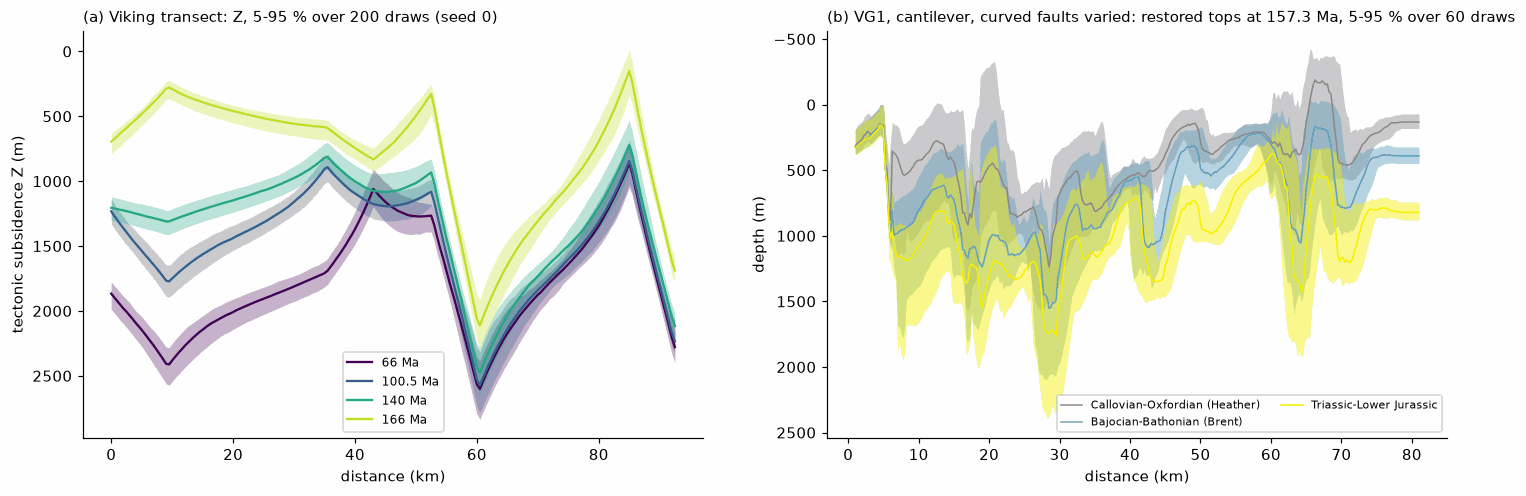

,dip0_0,dip0_1,dip0_2,dip0_3,dip0_4
mean,39.1,47.7,32.9,40.9,39.7
std,4.5,5.6,4.2,2.2,2.6
min,29.4,30.5,22.3,36.2,34.7
max,49.5,62.4,40.4,45.7,46.7


,age_Ma,"mean 5-95 % width, restored tops (m), faults fixed","mean 5-95 % width, restored tops (m), curves varied","mean 5-95 % width, Z (m)"
0,0.0,0.0,0.0,210.0
1,5.0,43.0,35.0,245.0
2,23.0,57.0,46.0,214.0
3,56.0,81.0,67.0,223.0
4,66.0,96.0,87.0,235.0
5,100.0,151.0,121.0,224.0
6,140.0,177.0,137.0,217.0
7,157.0,237.0,629.0,221.0
8,166.0,256.0,850.0,233.0
9,170.0,276.0,896.0,209.0


In [16]:
mcA = flex2d.monte_carlo_section(sec, n=200, seed=0, Te=TE, Te_sd=500.0)
mcB = flex2d.monte_carlo_section(vsec, vcurve, "cantilever", n=60, seed=0, Te=TE, Te_sd=500.0, Hd=8e3, beta=1.15, rift_end_Ma=155.0,
                                 vary_faults=True)
mcB0 = flex2d.monte_carlo_section(vsec, vcurve, "cantilever", n=60, seed=0, Te=TE, Te_sd=500.0, Hd=8e3, beta=1.15, rift_end_Ma=155.0)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for a, c in zip([66.0, 100.5, 140.0, 166.0], plt.cm.viridis(np.linspace(0, .9, 4))):
    i = int(np.argmin(np.abs(mcA.ages - a))); lo, mid, hi = mcA.envelope(i, None, "Z")
    ax[0].fill_between(mcA.x / 1e3, lo, hi, color=c, alpha=.3, lw=0); ax[0].plot(mcA.x / 1e3, mid, color=c, label=f"{mcA.ages[i]:g} Ma")
ax[0].invert_yaxis(); ax[0].set_xlabel("distance (km)"); ax[0].set_ylabel("tectonic subsidence Z (m)"); ax[0].legend(fontsize=8)
ax[0].set_title("(a) Viking transect: Z, 5-95 % over 200 draws (seed 0)", loc="left", fontsize=10)
iB = int(np.argmin(np.abs(mcB.ages - 157.3)))
flex2d.plot_mc_section(ax[1], mcB, iB, colors=VCOL, alpha=.45)
ax[1].set_title("(b) VG1, cantilever, curved faults varied: restored tops at 157.3 Ma, 5-95 % over 60 draws", loc="left", fontsize=10)
ax[1].legend(fontsize=7, ncol=2)
save(fig, "nb8_mc_envelopes.png"); plt.show()
display(mcB.params.filter(like="dip0").describe().loc[["mean", "std", "min", "max"]].round(1))
pd.DataFrame({"age_Ma": mcB.ages, "mean 5-95 % width, restored tops (m), faults fixed": mcB0.width("top"),
              "mean 5-95 % width, restored tops (m), curves varied": mcB.width("top"),
              "mean 5-95 % width, Z (m)": mcB.width("Z")}).round(0)

**Reading.** (a) The tectonic-subsidence envelopes widen with age, because more decompacted section and more paleo-water-depth uncertainty accumulate. They are a few hundred metres wide at 140–166 Ma, comparable with the misfit of the β fit above. (b) In the syn-rift restoration the envelopes are widest in the deep hangingwall troughs, where the thickest section is decompacted.

**Fault geometry varied.** The mid-ramp curves are drawn from their fit covariance (x_r, δ₀, λ). The drawn dips at the tip vary by ± 2–6° (1 σ). The post-rift tops (≤ 140 Ma) are unaffected, because the faults do not cut them. For the syn-rift and pre-rift tops (157–170 Ma) the mean 5–95 % width grows from 240–280 m (compaction, water depth and T_e only) to 630–900 m. **The fault geometry is the dominant source of uncertainty in the restored syn-rift section.**


## Choices, parameters and sources

Every modelling choice used in this notebook, with its value, the reason for it, and where it comes from (full references at the end).

| Parameter | Value used | Rationale | Source |
|---|---|---|---|
| Elastic thickness T_e | **1.5 km** (sensitivity runs 0, 1, 3, 10, 25 km) | These wells contain no sea-level markers, so T_e cannot be fitted here. The β misfit favours T_e = 0 only because the water depths are generic values. We therefore adopt the published calibrated value for the same graben. | Roberts et al. (1998), text discussing Fig. 4: best fit 1.5 km, acceptable 1.5–3 km, T_e = 0 rejected. Also used by Roberts et al. (2019). |
| Young's modulus E | 70 GPa | Single default in `pybasinsubs.constants` (also used by `flexure.py`, NB7). Roberts et al. use 100 GPa, which only rescales D: T_e(E=70) ≈ 1.13·T_e(E=100) for the same D. Fig. (b) of the validation uses E = 100 GPa for the comparison with Roberts. | Watts (2001) ch. 3; Turcotte & Schubert (2014) s. 3.9 |
| Poisson's ratio ν | 0.25 | Standard value for the lithosphere. | Turcotte & Schubert (2014); Roberts et al. (1998) p. 335 |
| Rigidity D | E·T_e³/12(1−ν²) = 2.1e19 N m at 1.5 km (1.68e20 at 3 km) | Thin elastic plate | Turcotte & Schubert (2014) eq. 3.72; Watts (2001) |
| Mantle density ρ_m (isostasy) | 3300 kg/m³ | `constants.RHO_M`; BasinSubs value, same as Roberts et al. (1998) isostasy and NB7 | Roberts et al. (1998) p. 335 |
| Water density ρ_w | 1025 kg/m³ (Roberts: 1000) | Seawater. The 2.5 % difference in Δρ has a negligible effect. | Allen & Allen (2013) ch. 9 |
| Infill of the unloaded basin | water | Water-loaded tectonic subsidence, the standard backstripping definition | Watts (2001) ch. 6; Allen & Allen (2013) ch. 9 |
| Grain densities ρ_g | shale 2720, sandstone 2650, chalk 2710 kg/m³ | Standard backstripping table | Sclater & Christie (1980) |
| Porosity law | φ = φ₀ exp(−z/C): shale φ₀ 0.63, C 1961 m; sandstone 0.49, 3704 m; chalk 0.70, 1409 m | Exponential compaction. Each mixed-lithology layer is decompacted by conserving grain thickness (Newton iteration). | Sclater & Christie (1980); Allen & Allen (2013) ch. 9 |
| Lithology fractions, ages, paleo-water depths | per Sodir group/formation | Generic group-level values; no per-well measurements | Sodir FactPages formation tops (factpages.sodir.no) plus the literature values in NB5/NB7 |
| Eustasy ΔSL | Miller et al. (2020) | Same curve as the 1D notebooks (Roberts used Haq et al. 1987) | Miller et al. (2020) |
| Load | q = (ρ_s − ρ_w) g S, with ρ_s the column bulk density | Sediment load in excess of water | Watts (2001) ch. 6; Roberts et al. (1998) |
| Plate type | continuous, solved by FFT (FD solver also available, both broken and continuous) | Rift-basin lithosphere is not broken. The broken-plate solver is provided for tests and for margins. | Turcotte & Schubert (2014) s. 3.17; Watts (2001) |
| Grid spacing dx | 500 m for the section; 50 m for the T_e→0 check | 500 m resolves λ ≥ 10 km loads. The finer grid places each well within 25 m of a node. | this work |
| Padding | none in `correlate` for the Viking line; the FFT solver pads internally; FD uses free ends | Beyond the end wells, thicknesses are held at the end wells' values | this work; padding as in NB7 `section_backstrip` (150 km) |
| Restoration mode A, bathymetric | seafloor = paleo-water depth, base = seafloor + decompacted S | Geometry follows from the data and does **not** depend on the isostasy model. Used for Z(x) and for ages > 140 Ma. | Allen & Allen (2013) ch. 9 |
| Restoration mode B, reverse post-rift | B = B₀ − (w₀ − w_t) − ΔZ_th + (SL_t − SL₀)·ρ_w/Δρ | Predicts paleo-water depth, so the isostasy model matters. Used for the restored-sequence figure, post-rift ages only. | Roberts et al. (1998) steps 1–6; Kusznir et al. (1995) |
| Thermal model | McKenzie (1978) instantaneous rifting: a = 125 km, T₁ = 1333 °C, α = 3.28e-5 /K, κ = 1e-6 m²/s, ρ_m = 3300 (same `constants.RHO_M` as the isostasy; McKenzie 1978 used 3330, about 1 % more thermal subsidence) | `thermal.MCK` (NB6) | McKenzie (1978); Allen & Allen (2013) ch. 3 |
| Stretching factor β | 1.26, fitted (grid 1.0–2.0, step 0.01) | Minimises RMS misfit to well paleo-water depths at post-rift ages. The broad minimum makes it a loose constraint. | this work; compare Roberts et al. (1998) Late Jurassic β ≈ 1.15 (range 1.1–1.2) |
| End of rifting | 140 Ma | Base Cretaceous (end of the Late Jurassic rift), as used for the Viking Graben | Roberts et al. (1998); Kusznir et al. (1995) |
| Fault geometry (VG1 demo) | 5 faults at 6.75, 19.0, 29.25, 44.25, 65.75 km, down to the east; throws per horizon read ±1.5 km | Positions and throws **digitized** from the published section | Roberts et al. (1998) Fig. 4a, p. 331 |
| Growth-strata slip (listric / domino) | Per step: D(x) = h(x) − h(x_FW) of the stripped unit; listric heave fitted by grid search (0–8 km, 50 m); domino φ = atan(−b), drop a from a linear fit | **Estimated.** Listric δ₀ fitted to digitized faces (30–75°), H_d = 10 km assumed; inclined shear angle 65° (default) and 60°, vertical shear not offered; 140 Ma relief assigned to the rift climax | Verrall (1981); White et al. (1986); Kusznir & Egan (1989); Roberts et al. (1998) |
| Fault dip, detachment, fill density | 45°, H_d = 8 km, ρ_f = 2400 kg/m³ | **Assumed.** Dip lies within the 31–50° steepest digitized fault faces; H_d is kept smaller than the 11–21 km block widths; syn-rift fill density | Kusznir et al. (1991, 1995) model; values assumed here |
| Faulting end / VG1 thermal | faults inactive after 140 Ma; rift end 155 Ma, β 1.15 | As in Roberts et al. (1998) Fig. 4b | Roberts et al. (1998) p. 331 |
| Transect | 8 Sodir wells, 29/6-1 → 31/6-1, projected onto longitude (≈ 92 km) | The only public wells with complete tops along a W–E line | Sodir FactPages |


## Validation summary (published or analytic vs ours)

| Test | Reference value | Ours | Source |
|---|---|---|---|
| Line load, continuous plate (T_e 10 km) | analytic w(x) | max error 0.03 % (FD), 0.00 % (FFT) | Turcotte & Schubert (2014) eq. 3.127 |
| Line load, broken plate | analytic w(x) | max error 0.01 % (FD) | Turcotte & Schubert (2014) eq. 3.135 |
| Load conservation ∫Δρ g w dx / ∫q dx | 1 | 1.00000 | equilibrium |
| T_e → 0 equals 1D Airy backstrip | 0 m | max 3.6 m (71 points, dx 50 m) | Watts (2001) ch. 6 |
| D at T_e = 3 km | ≈ 1.7e20 N m | 1.68e20 N m (E 70 GPa) | Roberts et al. (1998), section "2D backstripping using flexural isostasy" |
| 50 % flexural support, T_e = 1 km | λ ≈ 30 km | 28.0 km | Roberts et al. (1998) Fig. 7c, p. 335 |
| > 50 % support, T_e = 3 km | λ < 60 km | 63.8 km | Roberts et al. (1998) Fig. 7c, p. 335 |
| Best T_e, Viking Graben | 1.5 km (1.5–3) | adopted, not fitted | Roberts et al. (1998) Fig. 4; Roberts et al. (2019) |
| Late Jurassic β | ≈ 1.15 (1.1–1.2) | 1.26 (different wells, no sea-level markers) | Roberts et al. (1998) |
| Brent crest at base Cretaceous (VG1), T_e 1.5 km, β 1.15 | at about sea level; Airy: no part at sea level (Fig. 4b vs 4c, p. 331) | about 200 m (Airy about 383 m); qualitative agreement only | Roberts et al. (1998) |
| Cantilever, T_e → 0 | footwall 0; hangingwall −t(ρ_m−ρ_c)/(ρ_m−ρ_f) | exact (test) | local isostasy |

Roberts et al.'s restored sections are not published as numbers, so no point-by-point geometric comparison is possible.

## Fault restoration: what is done and what is not yet done
- **Done:** a flexural-cantilever fault restoration (planar faults, kinematic hangingwall collapse plus flexural-isostatic response, slips solved to match observed throws, heave closed). It runs together with stripping, decompaction and reverse post-rift modelling (`flex2d.restore_faulted`, section above). It is tested against the analytic Airy limit and against offset reproduction, and it is demonstrated on the published, digitized Viking Graben 1 section.
- **Not done on our 8-well transect.** The wells cannot locate faults or measure throws. That would need a depth-converted seismic line along the transect (licensed, or digitized from a publication that follows it), or explicitly *illustrative, estimated – not measured* faults.
- **Now done:** per-step slip from stripped growth-strata thickness, varying with x, with two mechanisms (listric + inclined simple shear; rigid domino rotation), selectable with `flex2d.restore(sec, faults, method='cantilever' | 'listric' | 'domino')`. Fault geometry can now be auto-detected, imported or traced by hand (Notebook 9). See the comparison section.
- **Fault planes and dip fits (Notebook 9 §7–9):** fault planes are drawn full length to the detachment H_d (figure above); dips and H_d can be fitted jointly to pre-rift flatness with a prior on the picked/detected dips, an effective-sample-size likelihood, conditional profile intervals and an AIC check (`faultfit.fit_fault_geometry`); the growth-strata methods can be coupled with the flexural-cantilever isostatic response (`flexural=True`, footwall uplift included); the 140 Ma relief assumption is a parameter (`relief_mode`, `relief_fraction`); the remaining misfit is shown as an ensemble band (`faultfit.restoration_ensemble`).
- **Simplifications compared with Kusznir et al. (1991, 1995):** the cantilever has no block rotation beyond the flexural response; the growth-strata methods' flexural coupling (optional) uses one amplitude per step and the top-surface displacement for the whole column; the cantilever's kinematic box uses the classic vertical collapse of Kusznir et al. (1991), while the listric option uses inclined shear only; no lower-crust/mantle pure-shear β profile; no syn-rift thermal reversal; no footwall erosion; a single, constant T_e for both faulting and loading.

## References
- Allen, P.A. & Allen, J.R. (2013) *Basin Analysis: Principles and Application to Petroleum Play Assessment*, 3rd ed. Wiley-Blackwell (ch. 2 flexure, ch. 3 rifting, ch. 9 subsidence history/backstripping).
- [Haq, Hardenbol & Vail (1987)](https://doi.org/10.1126/science.235.4793.1156), *Science* 235, 1156–1167.
- Kusznir, N.J. & Egan, S.S. (1989) Simple-shear and pure-shear models of extensional sedimentary basin formation: application to the Jeanne d'Arc Basin, Grand Banks of Newfoundland. *AAPG Memoir* 46, 305–322.
- Kusznir, N.J., Marsden, G. & Egan, S.S. (1991) A flexural-cantilever simple-shear/pure-shear model of continental lithosphere extension. *Geol. Soc. London Spec. Publ.* 56, 41–60.
- Kusznir, N.J., Roberts, A.M. & Morley, C.K. (1995) Forward and reverse modelling of rift basin formation. *Geol. Soc. London Spec. Publ.* 80, 33–56.
- Kusznir, N.J., Hunsdale, R. & Roberts, A.M. (2004) Timing of depth-dependent lithosphere stretching on the S. Lofoten rifted margin offshore mid-Norway: pre-breakup or post-breakup? *Basin Research* 16(2), 279–296, doi:10.1111/j.1365-2117.2004.00233.x (cited as an example of reverse post-rift modelling; details checked against the publisher record).
- McKenzie, D. (1978) Some remarks on the development of sedimentary basins. *Earth Planet. Sci. Lett.* 40, 25–32.
- Miller, K.G., Browning, J.V., Schmelz, W.J., Kopp, R.E., Mountain, G.S. & Wright, J.D. (2020) Cenozoic sea-level and cryospheric evolution from deep-sea geochemical and continental margin records. *Science Advances* 6, eaaz1346.
- Verrall, P. (1981) Structural interpretation with applications to North Sea problems. *JAPEC course notes* 3, London.
- White, N.J., Jackson, J.A. & McKenzie, D.P. (1986) The relationship between the geometry of normal faults and that of the sedimentary layers in their hanging walls. *J. Struct. Geol.* 8, 897–909.
- Roberts, A.M., Kusznir, N.J., Yielding, G. & Styles, P. (1998) 2D flexural backstripping of extensional basins: the need for a sideways glance. *Petroleum Geoscience* 4, 327–338 (D ≈ 1.7e20 N m in the section "2D backstripping using flexural isostasy"; Fig. 4 for T_e; Fig. 7c and p. 335 for the flexural-support curves).
- Roberts, A.M., Kusznir, N.J., Yielding, G. & Styles, P. (1998), Fig. 4a (p. 331): the present-day section of line Viking Graben 1, **digitized** here (see the fault-restoration section). The original interpretation is Roberts et al. (1993b) fig. 4, as cited by Roberts et al. (1998).
- Roberts, A.M., Kusznir, N.J., Yielding, G. & Beeley, H. (2019) Mapping the bathymetric evolution of the Northern North Sea: from Jurassic synrift archipelago through Cretaceous–Tertiary post-rift subsidence. *Petroleum Geoscience* 25, 306–321.
- Sclater, J.G. & Christie, P.A.F. (1980) Continental stretching: an explanation of the post-Mid-Cretaceous subsidence of the central North Sea basin. *J. Geophys. Res.* 85, 3711–3739.
- Sodir (Norwegian Offshore Directorate) FactPages: wellbore lithostratigraphy, https://factpages.sodir.no (accessed 2026).
- Turcotte, D.L. & Schubert, G. (2014) *Geodynamics*, 3rd ed. Cambridge University Press (s. 3.9–3.17, plate flexure; line-load solutions).
- Watts, A.B. (2001) *Isostasy and Flexure of the Lithosphere*. Cambridge University Press (ch. 3 elastic plate, ch. 6 backstripping).
